# Week 44, Monday lecture: convolutional neural networks — equivariance, pooling, the backward pass, a network from scratch, and PyTorch and TensorFlow on MNIST

**FYS-STK3155/4155, Monday October 26, 2026**

This notebook contains the code behind every figure and number in the Monday
slides (`week44slides.pdf`). It follows the lecture and finishes Chapter 10
(Sections 10.5–10.12) on top of the week-43 pieces: the convolutional layer
of Eq. (10.16), the arithmetic of Proposition 10.4, and three prescribed
filters on a digit.

*Part 1* is equivariance (Section 10.5). Theorem 10.7 says that convolution
is the *only* linear map that commutes with translation; we check it to
machine precision on a digit moved around a canvas, and we see Proposition
10.8 — a stride breaks it — in the same numbers.

*Part 2* is pooling and the receptive field (Section 10.6): max pooling
(Eq. 10.21) on the vertical-edge map of the week-43 five, its local
invariance (Proposition 10.9), and the receptive-field recursion of
Proposition 10.10 (Eq. 10.22) for three designs, including dilation
(Proposition 10.11).

*Part 3* is the backward pass (Section 10.8) and a network from scratch
(Section 10.9): the three gradients (10.29)–(10.31), the routing through a
max pool (10.33), the `im2col` implementation (10.34) of the book's
`cnn.py`, and the four checks of Section 10.9.2 — including the trap that a
ReLU/max-pool network cannot be gradient-checked naively.

*Part 4* measures whether any of it helps. (a) The experiment of Section
10.10 with our own NumPy network: on centred $8\times8$ digits a CNN is *not*
better than a dense network of the same size; on the same digits at random
offsets in a $12\times12$ frame it is, by seventeen points, with $2.5$ times
fewer parameters. (b) MNIST, the data of Project 2: our NumPy CNN, the
week-41 dense network (the Project 2 classifier), and the same two
architectures as complete PyTorch and TensorFlow/Keras programs (Section
10.12), with the parameter counts checked against Eq. (10.18), the
first-layer filters after training, and the ten-class confusion matrix of
week 43 for the convolutional network.

The functions are the ones in `make_week44_figures.py` (which imports
`make_week41_figures.py` and `make_week43_figures.py`); the seeds are 2026
for the NumPy networks and 1 for the frameworks (as in Section 10.12.5), so
that the figures here are the figures on the slides. Parts 1–3 run in
seconds, Part 4a in about a minute, the NumPy CNN on MNIST in about four
minutes, and each framework run in one to five minutes; the whole notebook
takes 15–25 minutes on a laptop CPU. PyTorch and TensorFlow are needed for
Part 4b only (`pip install torch tensorflow`); everything else runs with
NumPy, SciPy and scikit-learn.

**Tomorrow** (Tuesday) is cross-validation for your Project 2 network, the
subject of this week's exercises (`exercisesweek44.ipynb`, deadline
**Friday October 30**); Project 2 is due **November 6**.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

BLUE, RED, YELLOW, GREY = "#004488", "#BB5566", "#DDAA33", "#777777"
GREEN = "#228833"
SEED = 2026
POSITIVE_DIGIT = 5
np.set_printoptions(precision=4, suppress=True)

## The code of weeks 41 and 43, unchanged

The first cell is the week-41 dense network (activations, `create_layers`,
`feed_forward`, `backpropagation`, `train`, `load_mnist`), used in Part 4
as the Project 2 classifier. The second cell is the week-43 convolution
pieces: `cross_correlate2d` (Eq. 10.16 for one channel and one filter, as
four explicit loops), `max_pool2d` (Eq. 10.21), the three prescribed
filters, `conv_arithmetic` (Proposition 10.4) and the ten-class confusion
matrix. They are reproduced verbatim so that the notebook runs on its own.

In [2]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


def one_hot(y, n_classes=None):
    """Integer labels -> one-hot rows."""
    n_classes = int(np.max(y)) + 1 if n_classes is None else n_classes
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y


def load_mnist():
    """The 70 000 MNIST images as (X_train, y_train, X_test, y_test), pixels scaled to [0, 1], 784 columns.

    Looks for the repository's mnist.npz first (no download needed) and falls
    back on scikit-learn's fetch_openml, which downloads 70 000 images once.
    """
    here = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
    candidates = [os.path.join(here, "mnist.npz"),
                  os.path.join(here, "..", "BookPrograms", "chapter10_convolutional_networks", "mnist.npz"),
                  os.path.join(here, "..", "..", "BookML", "BookPrograms", "chapter10_convolutional_networks", "mnist.npz")]
    for path in candidates:
        if os.path.exists(path):
            d = np.load(path)
            X_train = d["x_train"].reshape(len(d["x_train"]), -1).astype(float) / 255.0
            X_test = d["x_test"].reshape(len(d["x_test"]), -1).astype(float) / 255.0
            return X_train, d["y_train"].astype(int), X_test, d["y_test"].astype(int)
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml("mnist_784", version=1, as_frame=False)
    X = mnist.data.astype(float) / 255.0
    y = mnist.target.astype(int)
    return X[:60000], y[:60000], X[60000:], y[60000:]



train_dense, dense_accuracy = train, accuracy      # the names used in Part 4

In [3]:
def cross_correlate2d(X, W, stride=1, padding=0):
    """Eq. (10.15)/(10.16) for one channel and one filter: Y(i,j) = sum_{m,n} X(Si+m-P, Sj+n-P) W(m,n)."""
    if padding:
        X = np.pad(X, padding)
    F = W.shape[0]
    H2 = (X.shape[0] - F) // stride + 1
    W2 = (X.shape[1] - F) // stride + 1
    Y = np.zeros((H2, W2))
    for i in range(H2):
        for j in range(W2):
            Y[i, j] = np.sum(X[stride * i:stride * i + F, stride * j:stride * j + F] * W)
    return Y


def max_pool2d(X, F=2, S=2):
    """Eq. (10.21): the largest value in each F x F window, windows S apart; no parameters."""
    H2, W2 = (X.shape[0] - F) // S + 1, (X.shape[1] - F) // S + 1
    Y = np.zeros((H2, W2))
    for i in range(H2):
        for j in range(W2):
            Y[i, j] = np.max(X[S * i:S * i + F, S * j:S * j + F])
    return Y



FILTERS = {"vertical edges": np.array([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]]),
           "horizontal edges": np.array([[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]]),
           "blur (mean)": np.ones((3, 3)) / 9.0}


def conv_arithmetic(H1, W1, C, K, F, S, P):
    """Proposition 10.1: output size, Eq. (10.17), and parameter count, Eq. (10.18)."""
    H2 = (H1 - F + 2 * P) // S + 1
    W2 = (W1 - F + 2 * P) // S + 1
    return H2, W2, K, K * (C * F * F + 1)


def confusion_matrix_multiclass(y_true, y_pred, n_classes):
    """C[i, j] = number of samples of true class i predicted as class j."""
    C = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(C, (np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)), 1)
    return C


def per_class_from_confusion(C):
    """Precision and recall of every class from the K x K matrix: each class against the rest."""
    tp = np.diag(C).astype(float)
    precision = tp / np.maximum(C.sum(axis=0), 1)
    recall = tp / np.maximum(C.sum(axis=1), 1)
    return precision, recall


In [4]:
X_train, y_train, X_test, y_test = load_mnist()
index = int(np.argmax(y_test == POSITIVE_DIGIT))        # test image 8, the week-43 five
five = X_test[index].reshape(28, 28)
Wv = FILTERS["vertical edges"]
print(f"MNIST: {len(X_train)} training and {len(X_test)} test images; the demonstration digit is test image {index}, label {y_test[index]}")

MNIST: 60000 training and 10000 test images; the demonstration digit is test image 8, label 5


## Part 1: equivariance (Section 10.5)

Let $T_s$ translate by $s$, $(T_s x)(i)=x(i-s)$. A map $\Phi$ is
*equivariant* to translation if $\Phi(T_s x)=T_s\Phi(x)$ for all $x$ and
$s$ (Definition 10.6, Eq. 10.20), and *invariant* if $\Phi(T_s x)=\Phi(x)$.
Equivariance says that moving the input moves the output by the same amount
and otherwise leaves it unchanged: a filter that responds to an edge responds
to that edge wherever it is. We want equivariance in the convolutional
layers (where features are) and invariance at the output (what the image
contains); pooling, in Part 2, converts one into the other.

**Theorem 10.7.** A linear map $\Phi$ is equivariant to all translations if
and only if it is a convolution, $\Phi(x)=w*x$. The easy direction is a
change of summation index. The other direction is the whole point: write
$w=\Phi(\delta)$ for the response to a unit impulse; any $x$ is a sum of
shifted impulses, $x=\sum_s x(s)\,T_s\delta$, so by linearity and
equivariance $\Phi(x)=\sum_s x(s)\,T_s\Phi(\delta)=\sum_s x(s)\,T_s w$,
whose $i$th component is $\sum_s x(s)w(i-s)=(w*x)(i)$. Once we demand a
linear map that commutes with translation, convolution is the only thing
left; the fall from $L^4$ parameters to $F^2$ is the exact price of the
symmetry. Read with Theorem 10.2 (a matrix is a convolution iff it is
Toeplitz): constant diagonals and commuting with translation are the same
statement.

Two qualifications matter in practice. **Proposition 10.8:** a convolution
with stride $S$ is equivariant to translations by multiples of $S$ only —
striding keeps the outputs at positions $Si$, and after a shift by $s$ the
retained set $\{Si+s\}$ is the same set iff $S\mid s$. And zero padding
computes the border rows from invented zeros, so equivariance holds in the
interior and fails within $F/2$ of the edge; the checks below are stated on
the interior.

The functions place the week-43 five on a $40\times40$ canvas of zeros (so
that `np.roll` never wraps the digit around), shift it, apply the
vertical-edge filter with stride 1 or 2, shift the feature map back and
subtract.

In [5]:
def place_on_canvas(img, size=40, offset=(6, 6)):
    """Put a 28x28 digit at a given offset (row, column) inside a size x size canvas of zeros."""
    canvas = np.zeros((size, size))
    r, c = offset
    canvas[r:r + img.shape[0], c:c + img.shape[1]] = img
    return canvas


def equivariance_discrepancy(X, W, shift, stride=1):
    """max |C_W(T_s X) - T_s C_W(X)| on the interior of the map, for Eq. (10.20).

    T_s is np.roll by `shift` (rows, columns); the digit sits on a canvas of
    zeros so that nothing wraps around.  With stride S the output index of a
    shift s is s/S, which is an integer only when S divides s (Proposition
    10.8): we compare after rolling the output back by -s/S and report the
    maximum over the interior (the border rows see the invented zeros of the
    canvas edge).
    """
    Y = cross_correlate2d(X, W, stride=stride)
    Xs = np.roll(np.roll(X, shift[0], axis=0), shift[1], axis=1)
    Ys = cross_correlate2d(Xs, W, stride=stride)
    back = (-int(round(shift[0] / stride)), -int(round(shift[1] / stride)))
    Ys_back = np.roll(np.roll(Ys, back[0], axis=0), back[1], axis=1)
    m = max(abs(shift[0]), abs(shift[1])) // stride + 2
    return float(np.max(np.abs(Y[m:-m, m:-m] - Ys_back[m:-m, m:-m]))), Y, Ys


def equivariance_table(img, W, shifts=((1, 0), (2, 0), (3, 0), (2, 3), (4, 2))):
    """Theorem 10.7 and Proposition 10.8 as numbers: discrepancy for S = 1 and S = 2."""
    X = place_on_canvas(img)
    rows = []
    for s in shifts:
        d1 = equivariance_discrepancy(X, W, s, stride=1)[0]
        d2 = equivariance_discrepancy(X, W, s, stride=2)[0]
        rows.append((s, d1, d2))
    return rows


def fig_equivariance(img, W=None, shift=(6, 9), fname="week44_equivariance.pdf"):
    """A five at two places, the two feature maps, and the shifted-back difference for stride 1 and stride 2."""
    W = FILTERS["vertical edges"] if W is None else W
    X = place_on_canvas(img, offset=(4, 4))
    Xs = np.roll(np.roll(X, shift[0], axis=0), shift[1], axis=1)
    d1, Y, Ys = equivariance_discrepancy(X, W, shift, stride=1)
    d2, Y2, Ys2 = equivariance_discrepancy(X, W, shift, stride=2)
    Ys_back = np.roll(np.roll(Ys, -shift[0], axis=0), -shift[1], axis=1)
    Ys2_back = np.roll(np.roll(Ys2, -shift[0] // 2, axis=0), -shift[1] // 2, axis=1)
    fig, ax = plt.subplots(2, 4, figsize=(12.5, 6.2))
    v = np.max(np.abs(Y))
    ax[0, 0].imshow(X, cmap="gray_r"); ax[0, 0].set_title("$x$", fontsize=10)
    ax[0, 1].imshow(Xs, cmap="gray_r"); ax[0, 1].set_title(f"$T_s x$, $s={shift}$", fontsize=10)
    ax[0, 2].imshow(Y, cmap="RdBu_r", vmin=-v, vmax=v); ax[0, 2].set_title("$\\mathcal{C}_w(x)$, $S=1$", fontsize=10)
    ax[0, 3].imshow(Ys, cmap="RdBu_r", vmin=-v, vmax=v); ax[0, 3].set_title("$\\mathcal{C}_w(T_s x)$, $S=1$", fontsize=10)
    ax[1, 0].imshow(Ys_back - Y, cmap="RdBu_r", vmin=-v, vmax=v)
    ax[1, 0].set_title(f"$T_{{-s}}\\mathcal{{C}}_w(T_s x)-\\mathcal{{C}}_w(x)$, $S=1$\nmax $|\\cdot|$ = {d1:.1e}", fontsize=10)
    v2 = np.max(np.abs(Y2))
    ax[1, 1].imshow(Y2, cmap="RdBu_r", vmin=-v2, vmax=v2); ax[1, 1].set_title("$\\mathcal{C}_w(x)$, $S=2$", fontsize=10)
    ax[1, 2].imshow(Ys2, cmap="RdBu_r", vmin=-v2, vmax=v2); ax[1, 2].set_title("$\\mathcal{C}_w(T_s x)$, $S=2$", fontsize=10)
    ax[1, 3].imshow(Ys2_back - Y2, cmap="RdBu_r", vmin=-v2, vmax=v2)
    ax[1, 3].set_title(f"shifted back and subtracted, $S=2$\nmax $|\\cdot|$ = {d2:.2f}", fontsize=10)
    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([])
    fig.tight_layout()
    fig.savefig(fname); fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return d1, d2


max |C_w(T_s x) - T_s C_w(x)| on the interior of the map
  shift (1, 0):  S=1 discrepancy 0.00e+00    S=2 discrepancy 2.267e+00  <- NOT equivariant
  shift (2, 0):  S=1 discrepancy 0.00e+00    S=2 discrepancy 0.000e+00  <- equivariant
  shift (3, 0):  S=1 discrepancy 0.00e+00    S=2 discrepancy 3.235e+00  <- NOT equivariant
  shift (2, 3):  S=1 discrepancy 0.00e+00    S=2 discrepancy 3.788e+00  <- NOT equivariant
  shift (4, 2):  S=1 discrepancy 0.00e+00    S=2 discrepancy 0.000e+00  <- equivariant


figure, shift (6,9): S=1 0.0e+00, S=2 3.99


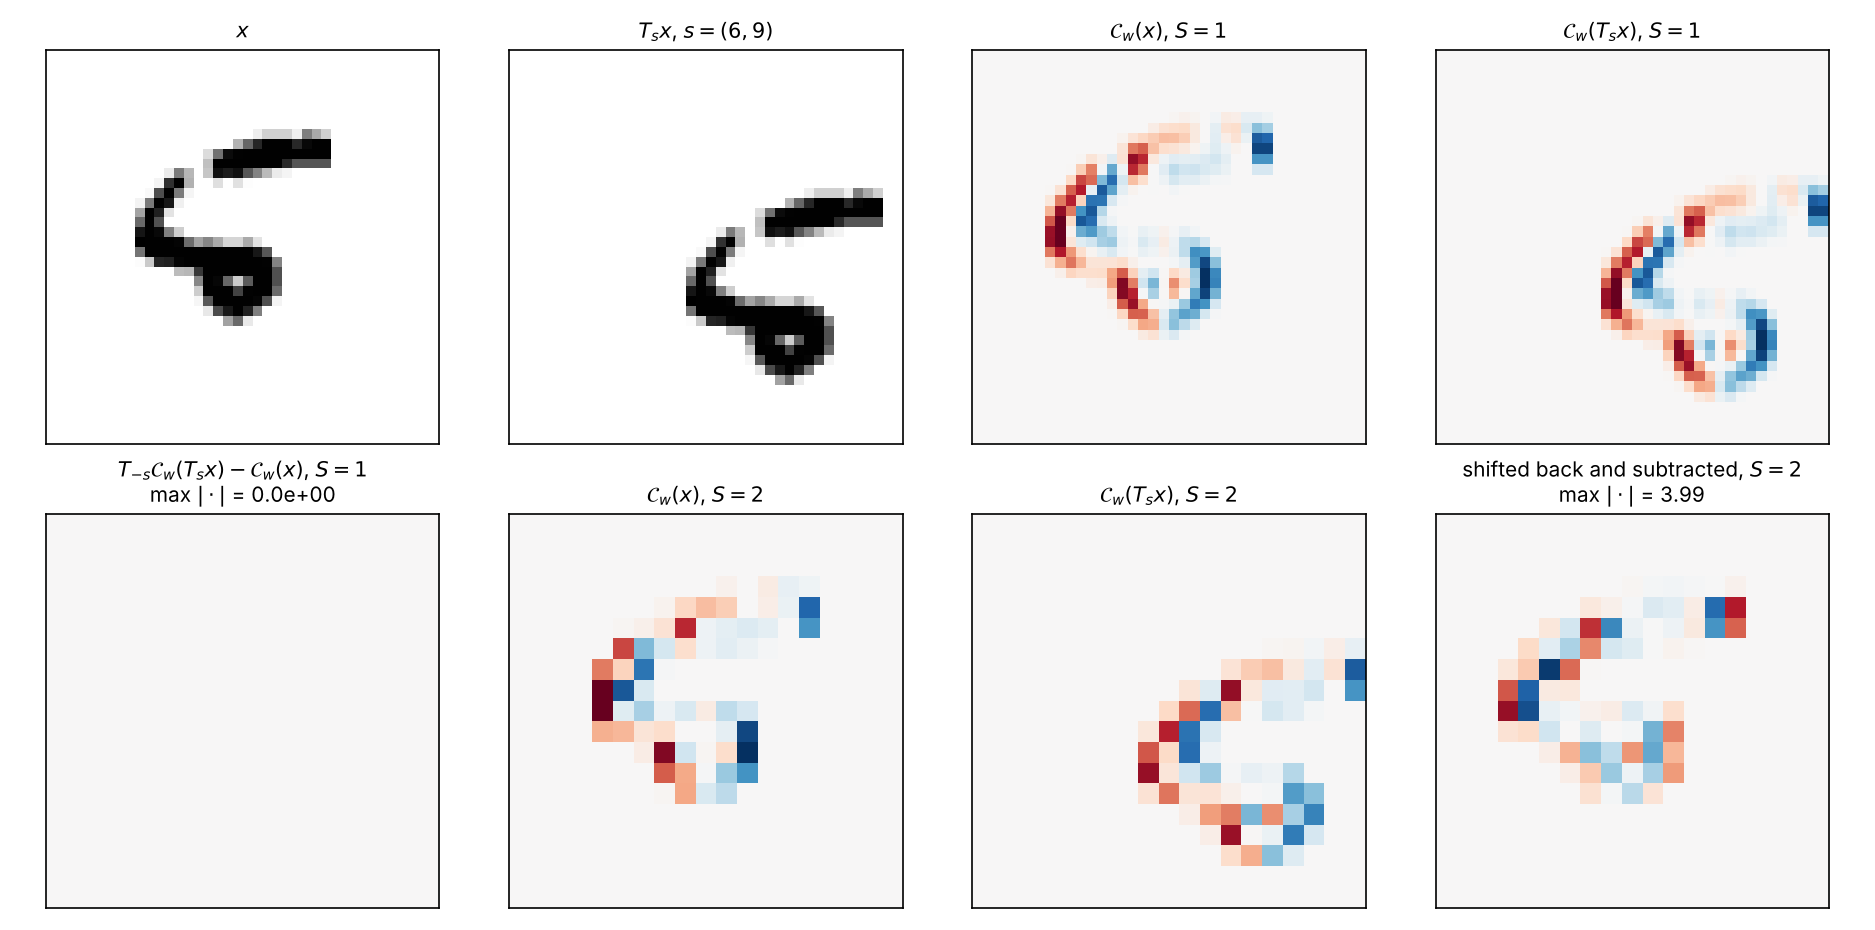

In [6]:
print("max |C_w(T_s x) - T_s C_w(x)| on the interior of the map")
for s, d1, d2 in equivariance_table(five, Wv):
    print(f"  shift {s}:  S=1 discrepancy {d1:.2e}    S=2 discrepancy {d2:.3e}  {'<- equivariant' if d2 < 1e-12 else '<- NOT equivariant'}")
d1, d2 = fig_equivariance(five)
print(f"figure, shift (6,9): S=1 {d1:.1e}, S=2 {d2:.2f}")
Image("week44_equivariance.png", width=1000)

The $S=1$ discrepancies are not $10^{-16}$ but *exactly zero*: the same
nine products are formed in the same order at the shifted position. With
$S=2$ the even shifts are exact and the odd ones are off by numbers of
order one on a map whose entries are of order one — a different subsample of
the same signal was kept, and no translation of the output reproduces it
(the book's own check gives $7.1$ for shift 1 at $S=2$, Section 10.9.2).
A dense layer has no such property: it would have to learn the five at
every position separately, which is what Table 10.1 in Part 4 measures.

## Part 2: pooling and the receptive field (Section 10.6)

A pooling layer slides a window of size $F$ with stride $S$ over each
channel independently and keeps one number per window,
$Y(c,i,j)=\max_{0\le m,n<F}X(c,Si+m,Sj+n)$ (Eq. 10.21), or the mean. It
has no trainable parameters and does not mix channels; with $F=S=2$ it
halves each side and discards three quarters of the activations.

**Proposition 10.9 (local invariance).** With $S=F$ and an input supported
in one window, a translation that keeps the support inside the window
leaves the pooled output unchanged — the maximum depends on the multiset of
values in the window, not on their arrangement — and a translation into
the next window leaves the value unchanged but moves it one index. Pooling
converts equivariance at the fine scale into invariance at the fine scale,
and a stack of conv–pool blocks builds invariance to displacements up to
the size of the last window measured in input pixels: the receptive field.

**Proposition 10.10 (receptive field).** For layers with filter sizes
$F_\ell$ and strides $S_\ell$, the number of input pixels along one axis
that can influence one output unit is $R_0=1$ and
$R_\ell=R_{\ell-1}+(F_\ell-1)\prod_{j<\ell}S_j$ (Eq. 10.22). With $3\times3$
filters at unit stride it grows only as $2\ell+1$; every pool of stride 2
doubles the multiplier. **Proposition 10.11 (dilation):** spreading the
taps $D$ apart costs no parameters, gives an effective size $D(F-1)+1$
(Eq. 10.24), and with $D_\ell=2^{\ell-1}$ the reach is $2^{L+1}-1$
(Eq. 10.25) — exponential in depth at full resolution.

In [7]:
def average_pool2d(X, F=2, S=2):
    """Average pooling: Eq. (10.21) with the maximum replaced by the mean."""
    H2, W2 = (X.shape[0] - F) // S + 1, (X.shape[1] - F) // S + 1
    Y = np.zeros((H2, W2))
    for i in range(H2):
        for j in range(W2):
            Y[i, j] = np.mean(X[S * i:S * i + F, S * j:S * j + F])
    return Y


def pooling_invariance(img, W=None, shifts=((1, 0), (1, 1), (2, 0), (2, 2))):
    """Proposition 10.9 in numbers: how much the max-pooled map changes when the input moves by s pixels.

    Reported as the fraction of pooled entries that change and the maximum
    change, for the pooled map compared with itself (shift inside a window
    leaves many entries fixed) and compared after shifting back by floor(s/2)
    (what equivariance at the coarse scale would predict).
    """
    W = FILTERS["vertical edges"] if W is None else W
    X = place_on_canvas(img, size=40, offset=(6, 6))
    P = max_pool2d(np.maximum(cross_correlate2d(X, W), 0.0))
    rows = []
    for s in shifts:
        Xs = np.roll(np.roll(X, s[0], axis=0), s[1], axis=1)
        Ps = max_pool2d(np.maximum(cross_correlate2d(Xs, W), 0.0))
        back = np.roll(np.roll(Ps, -(s[0] // 2), axis=0), -(s[1] // 2), axis=1)
        m = 3
        diff_raw = np.abs(Ps - P)[m:-m, m:-m]
        diff_back = np.abs(back - P)[m:-m, m:-m]
        rows.append((s, float(np.mean(diff_raw > 1e-12)), float(diff_raw.max()),
                     float(np.mean(diff_back > 1e-12)), float(diff_back.max())))
    return rows


def receptive_field(layers):
    """Eq. (10.22): R_l = R_{l-1} + (F_l - 1) prod_{j<l} S_j, for a list of (F, S) pairs; R_0 = 1."""
    R, prod_S, out = 1, 1, [1]
    for F, S in layers:
        R = R + (F - 1) * prod_S
        prod_S *= S
        out.append(R)
    return out


def receptive_field_dilated(F=3, L=5):
    """Proposition 10.11: unit stride, rates D_l = 2^(l-1), R_L = 2^(L+1) - 1."""
    R, out = 1, [1]
    for ell in range(1, L + 1):
        R = R + (2 ** (ell - 1)) * (F - 1)
        out.append(R)
    return out


def fig_pooling(img, W=None, fname="week44_pooling.pdf"):
    """The vertical-edge map after ReLU, max- and average-pooled, and the pooled map of the input moved one pixel."""
    W = FILTERS["vertical edges"] if W is None else W
    A = np.maximum(cross_correlate2d(img, W), 0.0)           # 26 x 26
    Pmax, Pavg = max_pool2d(A), average_pool2d(A)            # 13 x 13
    img1 = np.roll(img, 1, axis=1)                           # one pixel to the right
    P1 = max_pool2d(np.maximum(cross_correlate2d(img1, W), 0.0))
    changed = float(np.mean(np.abs(P1 - Pmax) > 1e-12))
    fig, ax = plt.subplots(1, 5, figsize=(14, 3.4))
    v = A.max()
    ax[0].imshow(img, cmap="gray_r"); ax[0].set_title("input $28\\times28$", fontsize=10)
    ax[1].imshow(A, cmap="Reds", vmin=0, vmax=v); ax[1].set_title("ReLU(vertical-edge map), $26\\times26$", fontsize=10)
    ax[2].imshow(Pmax, cmap="Reds", vmin=0, vmax=v); ax[2].set_title("max pool $F=S=2$: $13\\times13$", fontsize=10)
    ax[3].imshow(Pavg, cmap="Reds", vmin=0, vmax=v); ax[3].set_title("average pool $F=S=2$: $13\\times13$", fontsize=10)
    ax[4].imshow(P1, cmap="Reds", vmin=0, vmax=v)
    ax[4].set_title(f"max pool, input moved 1 px right\n{100 * changed:.0f}% of the entries changed", fontsize=10)
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    fig.tight_layout()
    fig.savefig(fname); fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return Pmax.shape, changed


def fig_receptive_field(fname="week44_receptive_field.pdf"):
    """R_l for plain 3x3 layers, for conv-pool blocks, and for exponentially dilated 3x3 layers (Eq. 10.22, Prop. 10.11)."""
    L = 6
    plain = receptive_field([(3, 1)] * L)
    blocks = receptive_field([(3, 1), (2, 2)] * (L // 2))      # conv, pool, conv, pool, ...
    dil = receptive_field_dilated(3, L)
    fig, ax = plt.subplots(figsize=(5.2, 3.4))
    ax.plot(range(L + 1), plain, "o-", color=BLUE, label="$3\\times3$, stride 1: $R_l=2l+1$")
    ax.plot(range(L + 1), blocks, "s-", color=RED, label="$3\\times3$ conv / $2\\times2$ pool alternating")
    ax.plot(range(L + 1), dil, "^-", color=GREEN, label="$3\\times3$ dilated, $D_l=2^{l-1}$: $2^{l+1}-1$")
    ax.set_xlabel("layer $l$"); ax.set_ylabel("receptive field $R_l$ (input pixels)")
    ax.set_yscale("log", base=2); ax.set_yticks([1, 2, 4, 8, 16, 32, 64, 128]); ax.set_yticklabels([1, 2, 4, 8, 16, 32, 64, 128])
    ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    fig.savefig(fname); fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return plain, blocks, dil


pooled map (13, 13); moving the input one pixel to the right changes 27.2% of the pooled entries
Proposition 10.9 in numbers (digit on a 40x40 canvas, ReLU of the vertical-edge map, max pool 2x2):
  shift (1, 0): pooled entries changed  27.2% (max change 2.27);  after shifting the pooled map back by floor(s/2):  27.2% (max 2.27)
  shift (1, 1): pooled entries changed  36.7% (max change 3.46);  after shifting the pooled map back by floor(s/2):  36.7% (max 3.46)
  shift (2, 0): pooled entries changed  37.9% (max change 2.89);  after shifting the pooled map back by floor(s/2):   0.0% (max 0.00)
  shift (2, 2): pooled entries changed  41.4% (max change 3.50);  after shifting the pooled map back by floor(s/2):   0.0% (max 0.00)


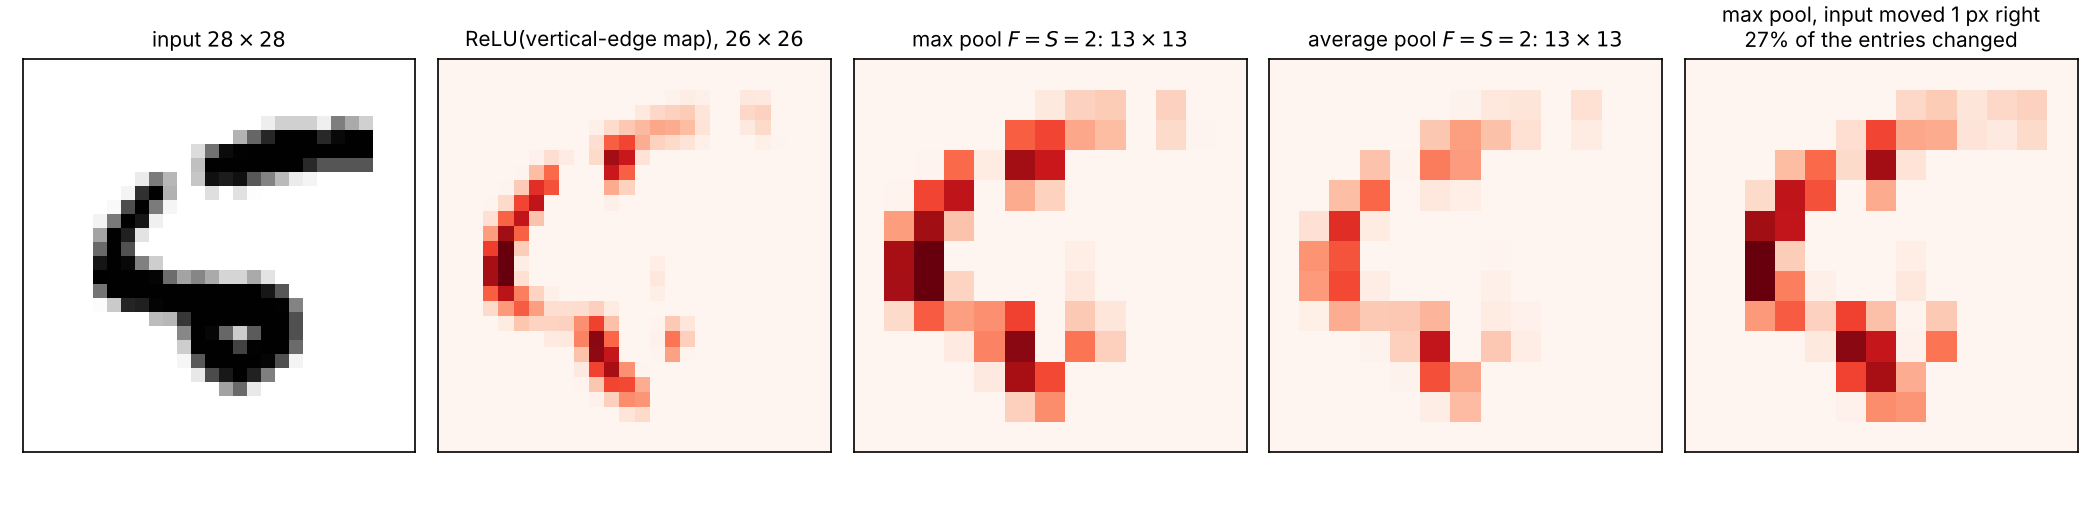

In [8]:
shape, changed = fig_pooling(five)
print(f"pooled map {shape}; moving the input one pixel to the right changes {100 * changed:.1f}% of the pooled entries")
print("Proposition 10.9 in numbers (digit on a 40x40 canvas, ReLU of the vertical-edge map, max pool 2x2):")
for s, fr, mx, frb, mxb in pooling_invariance(five):
    print(f"  shift {s}: pooled entries changed {100 * fr:5.1f}% (max change {mx:.2f});  after shifting the pooled map back by floor(s/2): {100 * frb:5.1f}% (max {mxb:.2f})")
Image("week44_pooling.png", width=1000)

R_l, plain 3x3 stride 1:          [1, 3, 5, 7, 9, 11, 13]
R_l, 3x3 conv / 2x2 pool blocks:  [1, 3, 4, 8, 10, 18, 22]
R_l, 3x3 dilated, D_l = 2^(l-1):  [1, 3, 7, 15, 31, 63, 127]
the network of Eq. (10.32), conv-pool-conv-pool: [1, 3, 4, 8, 10]


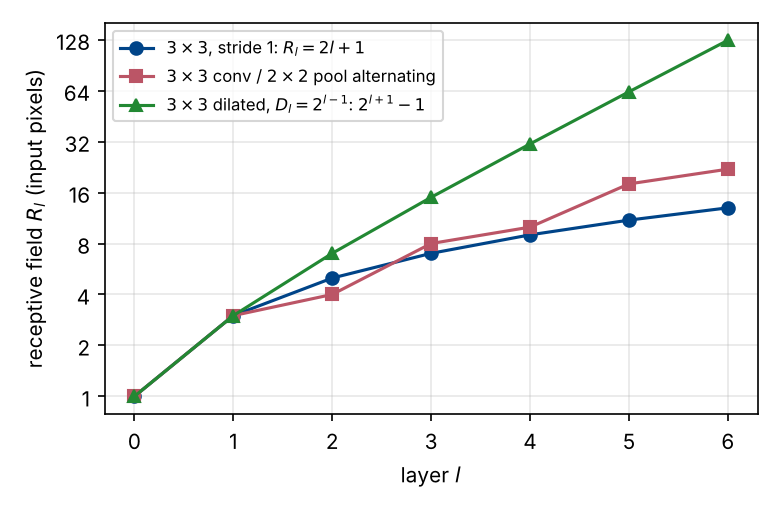

In [9]:
plain, blocks, dil = fig_receptive_field()
print(f"R_l, plain 3x3 stride 1:          {plain}")
print(f"R_l, 3x3 conv / 2x2 pool blocks:  {blocks}")
print(f"R_l, 3x3 dilated, D_l = 2^(l-1):  {dil}")
print(f"the network of Eq. (10.35), conv-pool-conv-pool: {receptive_field([(3, 1), (2, 2), (3, 1), (2, 2)])}")
Image("week44_receptive_field.png", width=520)

A one-pixel move changes about a quarter of the pooled entries (the
stroke crossed a window edge there) and leaves three quarters untouched; a
two-pixel move changes more entries but is a *pure shift* of the coarse
map — shifting it back leaves exactly zero. That is Proposition 10.9:
invariant to displacements inside a window, equivariant to larger ones.

The receptive field of the MNIST network of Eq. (10.35) is
$1\to3\to4\to8\to10$: each of the $7\times7\times64$ units at the end of the
trunk sees a $10\times10$ patch of the digit, and the dense head then sees
everything. Six plain $3\times3$ layers reach $13$ pixels, six alternating
conv/pool layers $22$, six dilated layers $127$ — the design rules of the
chapter (stack small filters, pool or dilate) in one plot.

## Part 3: the backward pass and a network from scratch (Sections 10.8–10.9)

Nothing changes in backpropagation: the network is a composition of
differentiable maps and the chain rule is the chain rule. With
$\delta(k,i,j)=\partial\mathcal{C}/\partial Z(k,i,j)$ the error at the output
of a convolutional layer, differentiating Eq. (10.16) gives

$$
\frac{\partial\mathcal{C}}{\partial W(k,c,m,n)}
=\sum_{i,j}\delta(k,i,j)\,X(c,Si+m-P,Sj+n-P)\qquad(10.29)
$$

— a cross-correlation of the input with the error, to which *every* output
position contributes (the price and the point of parameter sharing) —

$$
\frac{\partial\mathcal{C}}{\partial b(k)}=\sum_{i,j}\delta(k,i,j)\qquad(10.30),
\qquad
\frac{\partial\mathcal{C}}{\partial X(c,p,q)}
=\sum_k\sum_{i,j}\delta(k,i,j)\,W(k,c,p-Si+P,q-Sj+P)\qquad(10.31),
$$

which for $S=1$ is a convolution of $\delta$ with the spatially flipped
kernel: the forward pass correlates, the backward pass convolves. All three
are one fact — the forward map is linear with the unrolled matrix $W'$ of
Eq. (10.19), and backpropagation through any linear layer is multiplication
by its adjoint $W'^{\top}$; the adjoint is the *transposed convolution*
(Proposition 10.13), which runs forwards in every generative model of Part
IV. Through a max pool the derivative is a routing (Eq. 10.33): the
gradient flows only to the element that won the maximum, whose position is
stored in the forward pass.

**`im2col` (Eq. 10.34).** The six nested loops implied by (10.16) are
unusably slow in Python. Rearranging every $F\times F$ patch into a column
turns the convolution into one matrix product,
$Z=W_{\mathrm{flat}}\,\mathrm{im2col}(X)+b$, which BLAS executes at full
speed; the loops run over the filter, not over the image, and the backward
pass reuses the columns — (10.29) is the same `einsum` with the error in
place of the weights, and (10.31) scatters the columns back with `col2im`,
the adjoint of `im2col`. The code below is the book's
`BookPrograms/chapter10_convolutional_networks/cnn.py`, in the idiom of
week 41: parameters in a dictionary of arrays, a forward function that
returns the probabilities and a cache, a backward function that returns the
gradients, and Adam.

In [10]:
def pad2d(X, P):
    """Zero-pad the two spatial axes of X with shape (N, C, H, W)."""
    if P == 0:
        return X
    return np.pad(X, ((0, 0), (0, 0), (P, P), (P, P)), mode="constant")


def im2col(X, F, S, P):
    """Rearrange every F x F patch of X into a column, Eq. (10.34).

    X has shape (N, C, H, W); the result has shape (N, C*F*F, H2*W2) with
    H2 = (H - F + 2P)/S + 1, so that a convolution becomes one matrix product.
    """
    N, C, H, W = X.shape
    H2 = (H - F + 2 * P) // S + 1
    W2 = (W - F + 2 * P) // S + 1
    Xp = pad2d(X, P)
    cols = np.empty((N, C * F * F, H2 * W2))
    for i in range(F):
        for j in range(F):
            patch = Xp[:, :, i:i + S * H2:S, j:j + S * W2:S]      # (N,C,H2,W2)
            cols[:, (i * F + j)::F * F, :] = patch.reshape(N, C, -1)
    return cols


def col2im(cols, X_shape, F, S, P):
    """Adjoint of im2col: scatter columns back, accumulating overlaps."""
    N, C, H, W = X_shape
    H2 = (H - F + 2 * P) // S + 1
    W2 = (W - F + 2 * P) // S + 1
    Xp = np.zeros((N, C, H + 2 * P, W + 2 * P))
    for i in range(F):
        for j in range(F):
            patch = cols[:, (i * F + j)::F * F, :].reshape(N, C, H2, W2)
            np.add.at(Xp, (slice(None), slice(None),
                           slice(i, i + S * H2, S), slice(j, j + S * W2, S)), patch)
    return Xp if P == 0 else Xp[:, :, P:-P, P:-P]


def conv_forward(X, W, b, S=1, P=0):
    """Cross-correlation, Eq. (10.16).  W has shape (K, C, F, F)."""
    N, C, H, Wd = X.shape
    K, _, F, _ = W.shape
    H2 = (H - F + 2 * P) // S + 1
    W2 = (Wd - F + 2 * P) // S + 1
    cols = im2col(X, F, S, P)                       # (N, C*F*F, H2*W2)
    out = np.einsum("kd,ndp->nkp", W.reshape(K, -1), cols) + b[None, :, None]
    return out.reshape(N, K, H2, W2), cols


def conv_backward(dY, X, W, cols, S=1, P=0):
    """Gradients of the convolution, Eqs. (10.29), (10.30), (10.31)."""
    N, K, H2, W2 = dY.shape
    _, C, F, _ = W.shape
    dYf = dY.reshape(N, K, -1)                                   # (N,K,H2W2)
    dW = np.einsum("nkp,ndp->kd", dYf, cols).reshape(W.shape)
    db = dYf.sum(axis=(0, 2))
    dcols = np.einsum("kd,nkp->ndp", W.reshape(K, -1), dYf)
    dX = col2im(dcols, X.shape, F, S, P)
    return dX, dW, db


def maxpool_forward(X, F=2, S=2):
    """Max pooling, Eq. (10.21).  Returns the output and an argmax mask."""
    N, C, H, W = X.shape
    H2, W2 = (H - F) // S + 1, (W - F) // S + 1
    patches = np.empty((N, C, H2, W2, F * F))
    for i in range(F):
        for j in range(F):
            patches[..., i * F + j] = X[:, :, i:i + S * H2:S, j:j + S * W2:S]
    idx = patches.argmax(axis=-1)
    out = np.take_along_axis(patches, idx[..., None], axis=-1)[..., 0]
    return out, idx


def maxpool_backward(dY, X, idx, F=2, S=2):
    """Route each gradient to the argmax that produced it, Eq. (10.33)."""
    N, C, H, W = X.shape
    H2, W2 = dY.shape[2], dY.shape[3]
    dX = np.zeros_like(X)
    for i in range(F):
        for j in range(F):
            mask = (idx == i * F + j)
            np.add.at(dX, (slice(None), slice(None),
                           slice(i, i + S * H2, S), slice(j, j + S * W2, S)),
                      dY * mask)
    return dX


In [11]:
def relu_c(Z):
    return np.maximum(0.0, Z)


def relu_prime_c(Z):
    return (Z > 0).astype(Z.dtype)


def softmax_c(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)


def cross_entropy_c(probs, y_onehot):
    n = probs.shape[0]
    return -np.sum(y_onehot * np.log(probs + 1e-12)) / n


def init_cnn(C_in=1, K1=8, K2=16, F=3, n_out=10, flat=None, rng=None):
    """He initialisation, Eq. (8.74), with fan-in C*F*F for a convolution kernel."""
    rng = np.random.default_rng(0) if rng is None else rng

    def he(shape, fan_in):
        return rng.normal(0.0, np.sqrt(2.0 / fan_in), shape)
    return {
        "W1": he((K1, C_in, F, F), C_in * F * F), "b1": np.zeros(K1),
        "W2": he((K2, K1, F, F), K1 * F * F),     "b2": np.zeros(K2),
        "W3": he((flat, n_out), flat),            "b3": np.zeros(n_out),
    }


def cnn_forward(p, X):
    """Eq. (10.35): conv-ReLU-pool-conv-ReLU-pool-dense-softmax.  Returns the probabilities and the cache."""
    Z1, c1 = conv_forward(X, p["W1"], p["b1"], S=1, P=1)
    A1 = relu_c(Z1)
    P1, i1 = maxpool_forward(A1, 2, 2)
    Z2, c2 = conv_forward(P1, p["W2"], p["b2"], S=1, P=1)
    A2 = relu_c(Z2)
    P2, i2 = maxpool_forward(A2, 2, 2)
    flat = P2.reshape(P2.shape[0], -1)
    Z3 = flat @ p["W3"] + p["b3"]
    return softmax_c(Z3), (X, Z1, A1, i1, P1, c1, Z2, A2, i2, P2, flat, c2)


def cnn_backward(p, cache, probs, Y):
    """Backpropagation, Eqs. (10.29)-(10.33); delta^L = (a - y)/n as in week 41."""
    X, Z1, A1, i1, P1, c1, Z2, A2, i2, P2, flat, c2 = cache
    n = X.shape[0]
    d3 = (probs - Y) / n                                    # softmax + cross entropy
    g = {"W3": flat.T @ d3, "b3": d3.sum(axis=0)}
    dflat = d3 @ p["W3"].T
    dP2 = dflat.reshape(P2.shape)
    dA2 = maxpool_backward(dP2, A2, i2, 2, 2)
    dZ2 = dA2 * relu_prime_c(Z2)
    dP1, g["W2"], g["b2"] = conv_backward(dZ2, P1, p["W2"], c2, S=1, P=1)
    dA1 = maxpool_backward(dP1, A1, i1, 2, 2)
    dZ1 = dA1 * relu_prime_c(Z1)
    _, g["W1"], g["b1"] = conv_backward(dZ1, X, p["W1"], c1, S=1, P=1)
    return g


def cnn_accuracy(p, X, y, batch=1000):
    pred = np.concatenate([cnn_forward(p, X[s:s + batch])[0].argmax(axis=1) for s in range(0, len(X), batch)])
    return float((pred == y).mean())


def cnn_predict(p, X, batch=1000):
    return np.concatenate([cnn_forward(p, X[s:s + batch])[0].argmax(axis=1) for s in range(0, len(X), batch)])


def n_params(p):
    return sum(v.size for v in p.values())


def train_cnn(p, Xtr, Ytr, Xte, yte, epochs=20, batch=32, gamma=3e-3, rng=None, verbose=True):
    """Adam, Eqs. (4.51)-(4.55), on minibatches; one line of history per epoch (loss, test accuracy, seconds)."""
    rng = np.random.default_rng(0) if rng is None else rng
    m = {k: np.zeros_like(v) for k, v in p.items()}
    v = {k: np.zeros_like(val) for k, val in p.items()}
    b1, b2, eps, t = 0.9, 0.999, 1e-8, 0
    hist, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        order = rng.permutation(len(Xtr))
        tot = 0.0
        for s in range(0, len(order), batch):
            idx = order[s:s + batch]
            probs, cache = cnn_forward(p, Xtr[idx])
            tot += cross_entropy_c(probs, Ytr[idx]) * len(idx)
            g = cnn_backward(p, cache, probs, Ytr[idx])
            t += 1
            for k in p:
                m[k] = b1 * m[k] + (1 - b1) * g[k]
                v[k] = b2 * v[k] + (1 - b2) * g[k] ** 2
                p[k] -= gamma * (m[k] / (1 - b1 ** t)) / (np.sqrt(v[k] / (1 - b2 ** t)) + eps)
        acc = cnn_accuracy(p, Xte, yte)
        hist.append((ep, tot / len(Xtr), acc, time.time() - t0))
        if verbose:
            print(f"  epoch {ep:3d}  train loss {tot / len(Xtr):.4f}   test acc {acc:.4f}   {time.time() - t0:5.0f} s")
    return p, hist


### Four checks before training anything (Section 10.9.2)

In increasing order of strength: (1) `conv_forward` against the definition
(10.16) written as explicit loops; (2) the adjoint identity
$\langle\mathrm{im2col}\,x,y\rangle=\langle x,\mathrm{col2im}\,y\rangle$,
which must hold to rounding; (3) the analytic gradients against central
differences; (4) the whole network against central differences — where a
trap waits. We also rebuild the unrolled matrix of Eq. (10.19) column by
column from `conv_forward`.

In [12]:
def conv_naive(X, W, b, S=1, P=0):
    """Eq. (10.16) as four explicit loops, for checking conv_forward."""
    N, C, H, Wd = X.shape
    K, _, F, _ = W.shape
    H2 = (H - F + 2 * P) // S + 1
    W2 = (Wd - F + 2 * P) // S + 1
    Xp = pad2d(X, P)
    Y = np.zeros((N, K, H2, W2))
    for k in range(K):
        for i in range(H2):
            for j in range(W2):
                patch = Xp[:, :, S * i:S * i + F, S * j:S * j + F]
                Y[:, k, i, j] = np.sum(patch * W[k], axis=(1, 2, 3)) + b[k]
    return Y


def check_forward(rng, configs=((1, 0), (1, 1), (2, 1), (2, 0), (3, 2))):
    """im2col product against the explicit loops."""
    X = rng.normal(size=(2, 3, 7, 7))
    W = rng.normal(size=(4, 3, 3, 3))
    b = rng.normal(size=4)
    rows = []
    for S, P in configs:
        Y, _ = conv_forward(X, W, b, S, P)
        rows.append((S, P, Y.shape, float(np.max(np.abs(Y - conv_naive(X, W, b, S, P))))))
    return rows


def check_adjoint(rng, configs=((3, 1, 0), (3, 2, 1), (5, 1, 2))):
    """<im2col(x), y> = <x, col2im(y)>: the backward pass is the adjoint (notebox of Section 10.8)."""
    rows = []
    for F, S, P in configs:
        X = rng.normal(size=(2, 3, 9, 9))
        cols = im2col(X, F, S, P)
        Y = rng.normal(size=cols.shape)
        lhs = np.sum(cols * Y)
        rhs = np.sum(X * col2im(Y, X.shape, F, S, P))
        rows.append((F, S, P, float(abs(lhs - rhs))))
    return rows


def check_gradients(rng, configs=((1, 0), (1, 1), (2, 1)), h=1e-6):
    """Central differences against Eqs. (10.29)-(10.31) and (10.33), on a scalar cost 0.5 ||Y||^2."""
    rows = []
    for S, P in configs:
        X = rng.normal(size=(2, 2, 6, 6))
        W = rng.normal(size=(3, 2, 3, 3))
        b = rng.normal(size=3)
        Y, cols = conv_forward(X, W, b, S, P)
        dX, dW, db = conv_backward(Y, X, W, cols, S, P)       # dC/dY = Y for C = 0.5 ||Y||^2

        def fd(arr, grad, name, n_samples=10):
            idx = [tuple(rng.integers(0, s) for s in arr.shape) for _ in range(n_samples)]
            worst = 0.0
            for ix in idx:
                arr[ix] += h
                cp = 0.5 * np.sum(conv_forward(X, W, b, S, P)[0] ** 2)
                arr[ix] -= 2 * h
                cm = 0.5 * np.sum(conv_forward(X, W, b, S, P)[0] ** 2)
                arr[ix] += h
                worst = max(worst, abs((cp - cm) / (2 * h) - grad[ix]) / (abs(grad[ix]) + 1e-12))
            return worst
        rows.append((S, P, fd(X, dX, "X"), fd(W, dW, "W"), fd(b, db, "b")))
    # max pooling, Eq. (10.33)
    X = rng.normal(size=(2, 2, 6, 6))
    out, idx = maxpool_forward(X)
    dX = maxpool_backward(out, X, idx)                        # C = 0.5 ||out||^2
    worst = 0.0
    for ix in [tuple(rng.integers(0, s) for s in X.shape) for _ in range(20)]:
        X[ix] += h; cp = 0.5 * np.sum(maxpool_forward(X)[0] ** 2)
        X[ix] -= 2 * h; cm = 0.5 * np.sum(maxpool_forward(X)[0] ** 2)
        X[ix] += h
        worst = max(worst, abs((cp - cm) / (2 * h) - dX[ix]))
    return rows, worst


def check_network_gradient(X, Y, rng, h=1e-5, n_samples=8):
    """The whole ReLU/max-pool network on real images against central differences: W1, W2, W3, b3 agree to 1e-8,
    the two convolutional biases do not (the notebox of Section 10.9.2: a bias shifts a whole feature map, and the
    difference quotient straddles a ReLU kink or a change of argmax in some max-pool window)."""
    p = init_cnn(flat=16 * (X.shape[2] // 4) ** 2, rng=rng)
    probs, cache = cnn_forward(p, X)
    g = cnn_backward(p, cache, probs, Y)
    out = {}
    for k in p:
        worst = 0.0
        for ix in [tuple(rng.integers(0, s) for s in p[k].shape) for _ in range(n_samples)]:
            p[k][ix] += h; cp = cross_entropy_c(cnn_forward(p, X)[0], Y)
            p[k][ix] -= 2 * h; cm = cross_entropy_c(cnn_forward(p, X)[0], Y)
            p[k][ix] += h
            worst = max(worst, abs((cp - cm) / (2 * h) - g[k][ix]) / (abs(g[k][ix]) + 1e-10))
        out[k] = worst
    return out


def unrolled_matrix(W):
    """Eq. (10.19): the 4 x 9 matrix of a 2x2 filter on a 3x3 input, reconstructed column by column from conv_forward."""
    cols = []
    for e in range(9):
        X = np.zeros((1, 1, 3, 3)); X.ravel()[e] = 1.0
        cols.append(conv_forward(X, W[None, None], np.zeros(1))[0].ravel())
    return np.array(cols).T


In [13]:
rng = np.random.default_rng(SEED)
print("1. the im2col product against the explicit loops of (10.16)")
for S, P, shape, err in check_forward(rng):
    print(f"   S={S} P={P}  shape {shape}  max|conv - naive| = {err:.3e}")
print("2. the adjoint identity <im2col x, y> = <x, col2im y>")
for F, S, P, err in check_adjoint(rng):
    print(f"   F={F} S={S} P={P}:  |<Ax,y> - <x,A*y>| = {err:.2e}")
print("3. central differences against (10.29)-(10.31) and (10.33), relative errors")
rows, pool_err = check_gradients(rng)
for S, P, eX, eW, eb in rows:
    print(f"   S={S} P={P}:  dX {eX:.2e}   dW {eW:.2e}   db {eb:.2e}")
print(f"   max pool: dX {pool_err:.2e}")
print("4. the whole ReLU/max-pool network on four MNIST images, relative errors")
netcheck = check_network_gradient(X_train[:4].reshape(4, 1, 28, 28), one_hot(y_train[:4], 10), np.random.default_rng(SEED))
print("   " + "   ".join(f"{k} {v:.1e}" for k, v in netcheck.items()))
print("the unrolled matrix (10.19) of the 2x2 filter [[1,2],[3,4]] on a 3x3 input, rebuilt from conv_forward:")
print(unrolled_matrix(np.array([[1.0, 2.0], [3.0, 4.0]])))

1. the im2col product against the explicit loops of (10.16)
   S=1 P=0  shape (2, 4, 5, 5)  max|conv - naive| = 3.553e-15
   S=1 P=1  shape (2, 4, 7, 7)  max|conv - naive| = 3.553e-15
   S=2 P=1  shape (2, 4, 4, 4)  max|conv - naive| = 3.553e-15
   S=2 P=0  shape (2, 4, 3, 3)  max|conv - naive| = 2.665e-15
   S=3 P=2  shape (2, 4, 3, 3)  max|conv - naive| = 3.553e-15
2. the adjoint identity <im2col x, y> = <x, col2im y>
   F=3 S=1 P=0:  |<Ax,y> - <x,A*y>| = 1.42e-14
   F=3 S=2 P=1:  |<Ax,y> - <x,A*y>| = 3.55e-15
   F=5 S=1 P=2:  |<Ax,y> - <x,A*y>| = 2.84e-14
3. central differences against (10.26)-(10.28) and (10.30), relative errors
   S=1 P=0:  dX 1.32e-07   dW 1.35e-08   db 2.53e-09
   S=1 P=1:  dX 7.38e-08   dW 2.24e-08   db 7.92e-09
   S=2 P=1:  dX 6.58e-08   dW 1.06e-08   db 1.03e-08
   max pool: dX 1.22e-09
4. the whole ReLU/max-pool network on four MNIST images, relative errors


   W1 3.9e-09   b1 2.0e+00   W2 7.5e-09   b2 1.4e+00   W3 5.8e-09   b3 5.3e-10
the unrolled matrix (10.19) of the 2x2 filter [[1,2],[3,4]] on a 3x3 input, rebuilt from conv_forward:
[[1. 2. 0. 3. 4. 0. 0. 0. 0.]
 [0. 1. 2. 0. 3. 4. 0. 0. 0.]
 [0. 0. 0. 1. 2. 0. 3. 4. 0.]
 [0. 0. 0. 0. 1. 2. 0. 3. 4.]]


Checks 1–3 pass at rounding level: the product equals the definition, the
backward pass is the adjoint, and the gradients are right. Check 4 is the
trap of the notebox in Section 10.9.2: $W_1$, $W_2$, $W_3$ and $b_3$ agree
to $10^{-8}$, but the two convolutional biases do not — $b_1$ is off by a
factor of order ten, for $h=10^{-6}$, $10^{-5}$ and $10^{-4}$ alike. This is
not a bug. A bias shifts an *entire feature map*, so the perturbation pushes
some pre-activation across the ReLU kink or changes which element wins a
max-pool window; the network is piecewise linear, the central difference
straddles a kink, and the quotient converges to nothing in particular. The
book repeats the check with $\tanh$ and average pooling — smooth everywhere,
same backward-pass code paths — and all six arrays agree to $10^{-7}$. The
lesson is general: *verify gradients on a smooth surrogate, then switch the
activations back.*

What the four checks do **not** establish is that our cross-correlation is
the *same* cross-correlation as the libraries': a transposed kernel or an
off-by-one in the padding applied consistently in both passes would pass
all four. That is settled in Section 10.12.3 by loading one set of weights
into our code, PyTorch and Keras and comparing all six gradients, which
agree to $4.4\times10^{-16}$.

## Part 4a: does it help? The experiment of Section 10.10

The arguments of Sections 10.1 and 10.5 are arguments; this section
measures. The $1797$ scikit-learn digits ($8\times8$), split $70/30$, the
network of Eq. (10.35) with $K_1=8$, $K_2=16$ against a one-hidden-layer
dense network of the same size, both trained by Adam with
$\gamma=3\times10^{-3}$ for twenty epochs in batches of $32$, five seeds.
First the digits as supplied, centred; then the same digits placed at a
uniformly random offset inside a $12\times12$ frame (`place_digits`). The
dense network uses the same Adam as the CNN so that only the architecture
differs (`train_dense_adam`); the hidden widths $25$ and $44$ match the
parameter counts of Table 10.1 as closely as a dense net can.

In [14]:
def place_digits(imgs, rng, out=12):
    """Put each 8x8 digit at a random offset inside an out x out canvas (N, 1, out, out)."""
    n = len(imgs)
    C = np.zeros((n, 1, out, out))
    for k in range(n):
        i, j = rng.integers(0, out - 8 + 1, size=2)
        C[k, 0, i:i + 8, j:j + 8] = imgs[k]
    return C


def train_dense_adam(Xtr, Ytr, Xte, yte, hidden, seed, epochs=20, batch=32, gamma=3e-3):
    """A one-hidden-layer ReLU softmax network trained by the same Adam as the CNN (the dense model of Table 10.1)."""
    rng = np.random.default_rng(seed)
    Xf, Xef = Xtr.reshape(len(Xtr), -1), Xte.reshape(len(Xte), -1)
    D = Xf.shape[1]
    P = {"W1": rng.normal(0, np.sqrt(2 / D), (D, hidden)), "b1": np.zeros(hidden),
         "W2": rng.normal(0, np.sqrt(2 / hidden), (hidden, 10)), "b2": np.zeros(10)}
    m = {k: np.zeros_like(v) for k, v in P.items()}
    v_ = {k: np.zeros_like(v) for k, v in P.items()}
    t, hist = 0, []
    for ep in range(epochs):
        order = rng.permutation(len(Xf))
        for s in range(0, len(order), batch):
            i = order[s:s + batch]
            xb, yb = Xf[i], Ytr[i]
            n = len(i)
            Z1 = xb @ P["W1"] + P["b1"]
            A1 = relu_c(Z1)
            pr = softmax_c(A1 @ P["W2"] + P["b2"])
            d2 = (pr - yb) / n
            g = {"W2": A1.T @ d2, "b2": d2.sum(0)}
            d1 = (d2 @ P["W2"].T) * relu_prime_c(Z1)
            g["W1"], g["b1"] = xb.T @ d1, d1.sum(0)
            t += 1
            for k in P:
                m[k] = 0.9 * m[k] + 0.1 * g[k]
                v_[k] = 0.999 * v_[k] + 0.001 * g[k] ** 2
                P[k] -= gamma * (m[k] / (1 - 0.9 ** t)) / (np.sqrt(v_[k] / (1 - 0.999 ** t)) + 1e-8)
        pr = softmax_c(relu_c(Xef @ P["W1"] + P["b1"]) @ P["W2"] + P["b2"])
        hist.append(float((pr.argmax(1) == yte).mean()))
    return hist, sum(v.size for v in P.values())


def digits_experiment(seeds=5, epochs=20, verbose=False):
    """Table 10.1: CNN against dense on the scikit-learn digits, centred 8x8 and at random offsets in 12x12."""
    from sklearn.datasets import load_digits
    from sklearn.model_selection import train_test_split
    d = load_digits()
    imgs, y = d.images / 16.0, d.target
    itr, ite, ytr, yte = train_test_split(imgs, y, test_size=0.3, random_state=42, stratify=y)
    Ytr = one_hot(ytr, 10)
    out = {}
    for canvas, hidden in [(8, 25), (12, 44)]:
        ca, da, curves_c, curves_d = [], [], [], []
        for seed in range(seeds):
            rng = np.random.default_rng(100 + seed)
            Xtr = place_digits(itr, rng, canvas) if canvas > 8 else itr[:, None]
            Xte = place_digits(ite, rng, canvas) if canvas > 8 else ite[:, None]
            p = init_cnn(flat=16 * (canvas // 4) ** 2, rng=np.random.default_rng(seed))
            p, h = train_cnn(p, Xtr, Ytr, Xte, yte, epochs=epochs, batch=32, gamma=3e-3,
                             rng=np.random.default_rng(seed), verbose=False)
            ca.append(h[-1][2]); curves_c.append([r[2] for r in h]); npar_c = n_params(p)
            hd, npar_d = train_dense_adam(Xtr, Ytr, Xte, yte, hidden, seed, epochs=epochs)
            da.append(hd[-1]); curves_d.append(hd)
            if seed == 0:
                filters = p["W1"][:, 0].copy()
            if verbose:
                print(f"  {canvas}x{canvas} seed {seed}: CNN {ca[-1]:.4f}  dense {da[-1]:.4f}")
        out[canvas] = {"cnn": np.array(ca), "dense": np.array(da), "n_cnn": npar_c, "n_dense": npar_d,
                       "curves_cnn": np.array(curves_c), "curves_dense": np.array(curves_d), "filters": filters,
                       "n_train": len(itr), "n_test": len(ite)}
    return out


def fig_digits(res, fname="week44_digits.pdf"):
    """Section 10.10 reproduced: (a) accuracy against epoch, (b) the bars, (c) the eight learned first-layer filters."""
    fig = plt.figure(figsize=(13, 3.9))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1.0, 1.0], wspace=0.3)
    ax0 = fig.add_subplot(gs[0])
    ep = np.arange(1, res[8]["curves_cnn"].shape[1] + 1)
    for canvas, ls in [(8, "-"), (12, "--")]:
        tag = "" if canvas == 8 else " random offset"
        ax0.plot(ep, res[canvas]["curves_cnn"].mean(0), ls, color=BLUE, label=f"CNN, {canvas}$\\times${canvas}{tag}")
        ax0.plot(ep, res[canvas]["curves_dense"].mean(0), ls, color=RED, label=f"dense, {canvas}$\\times${canvas}{tag}")
    ax0.set_xlabel("epoch"); ax0.set_ylabel("test accuracy (mean of 5 seeds)"); ax0.grid(alpha=0.3)
    ax0.legend(fontsize=8); ax0.set_title("(a) learning curves", fontsize=10)
    ax1 = fig.add_subplot(gs[1])
    labels, means, lo, hi, cols = [], [], [], [], []
    for canvas in (8, 12):
        for model, col in [("cnn", BLUE), ("dense", RED)]:
            a = res[canvas][model]
            labels.append(f"{'CNN' if model == 'cnn' else 'dense'}\n{res[canvas]['n_' + model]}")
            means.append(a.mean()); lo.append(a.mean() - a.min()); hi.append(a.max() - a.mean()); cols.append(col)
    x = np.array([0, 1, 2.5, 3.5])
    ax1.bar(x, means, color=cols, yerr=[lo, hi], capsize=4, alpha=0.9, width=0.8)
    ax1.set_xticks(x); ax1.set_xticklabels(labels, fontsize=8); ax1.set_ylim(0.5, 1.02)
    ax1.set_ylabel("test accuracy, mean and range"); ax1.set_title("(b) centred $8\\times8$  |  random offset $12\\times12$", fontsize=10)
    for xi, m_, h_ in zip(x, means, hi):
        ax1.text(xi, m_ + h_ + 0.012, f"{m_:.3f}", ha="center", fontsize=8)
    ax1.set_xlabel("model and number of parameters", fontsize=8)
    sub = gs[2].subgridspec(2, 4, wspace=0.15, hspace=0.15)
    F = res[12]["filters"]; v = np.max(np.abs(F))
    for k in range(8):
        a = fig.add_subplot(sub[k // 4, k % 4])
        a.imshow(F[k], cmap="RdBu_r", vmin=-v, vmax=v); a.set_xticks([]); a.set_yticks([])
        if k == 1:
            a.set_title("(c) the eight learned $3\\times3$ filters ($12\\times12$, seed 0)", fontsize=10, x=1.1)
    fig.savefig(fname, bbox_inches="tight"); fig.savefig(fname.replace(".pdf", ".png"), dpi=150, bbox_inches="tight")
    plt.close(fig)


Table 10.1 reproduced: mean test accuracy over five seeds (min-max)
  8x8 centred      : CNN    1898 parameters  0.9656 (0.9574-0.9704)
                      dense  1885 parameters  0.9670 (0.9593-0.9704)
  12x12 random offset: CNN    2698 parameters  0.8774 (0.8574-0.9185)
                      dense  6830 parameters  0.7070 (0.6815-0.7315)


57 s


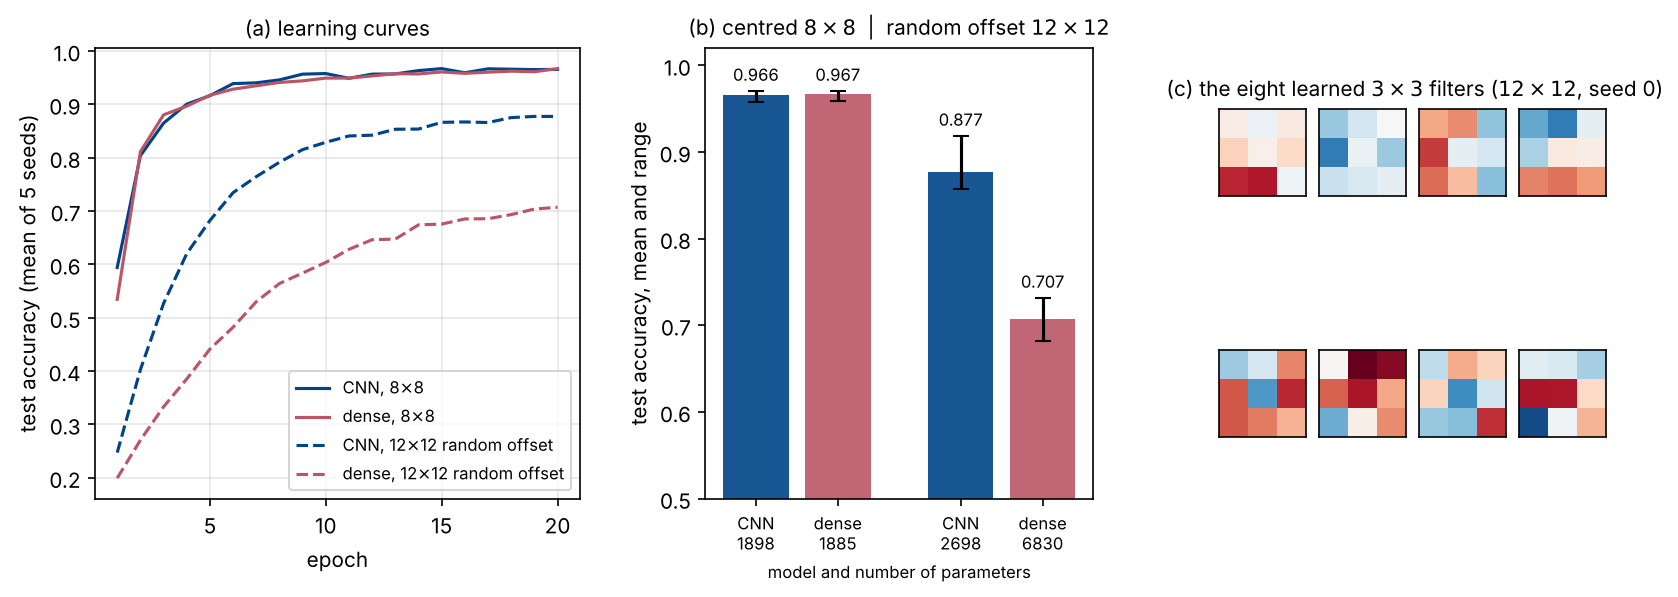

In [15]:
t0 = time.time()
res = digits_experiment(seeds=5, epochs=20)
print("Table 10.1 reproduced: mean test accuracy over five seeds (min-max)")
for canvas in (8, 12):
    r = res[canvas]
    print(f"  {canvas}x{canvas}{' centred      ' if canvas == 8 else ' random offset'}: "
          f"CNN   {r['n_cnn']:5d} parameters  {r['cnn'].mean():.4f} ({r['cnn'].min():.4f}-{r['cnn'].max():.4f})")
    print(f"  {' ' * 20}dense {r['n_dense']:5d} parameters  {r['dense'].mean():.4f} ({r['dense'].min():.4f}-{r['dense'].max():.4f})")
fig_digits(res)
print(f"{time.time() - t0:.0f} s")
Image("week44_digits.png", width=1000)

The numbers reproduce Table 10.1 of the book to the digit (same code,
same seeds). The first block is a negative result and we report it as such:
on centred $8\times8$ digits the convolutional network is *not* better,
$0.9656$ against $0.9670$, far inside the seed-to-seed spread of both. With
matched parameter counts the two architectures are indistinguishable — not
a failure of the implementation but a statement about the data. The digits
are $64$ pixels, pre-centred and pre-scaled; there is almost no translation
for equivariance to exploit, and a dense layer can afford one weight per
pixel per hidden unit.

The second block is where the argument lands. Placing the same digits at a
random offset in a slightly larger frame — a change a human would not
notice — costs the dense network twenty-six points, from $0.9670$ to
$0.7070$, and the convolutional network nine, from $0.9656$ to $0.8774$.
The CNN wins by seventeen points *with $2.5$ times fewer parameters*. The
dense network must learn each digit separately at each of the twenty-five
positions from $1257$ training images; the convolutional network learns
each feature once (Theorem 10.7), and pooling supplies the tolerance to
where it landed (Proposition 10.9). Panel (c): the eight first-layer filters,
initialised at random and trained only against a classification loss, have
become oriented patterns with a positive lobe beside a negative one — edge
detectors of the kind signal processing prescribes by hand, and nobody
asked for them.

## Part 4b: MNIST — our NumPy CNN, the week-41 dense network, PyTorch and Keras (Section 10.12)

Now the $70\,000$ MNIST images that Project 2 is about, with six models:

- **dense 784–100–10**, ReLU, softmax ($79\,510$ parameters) — the week-41
  network, the Project 2 classifier: in NumPy with the week-41 plain SGD
  ($\gamma=0.1$, batches of $100$), and in PyTorch and Keras with Adam;
- **the CNN of Eq. (10.35) with $K=32,64$ and a dense head of $1024$**
  (Figure 10.11): $3\,241\,354$ parameters, dropout $0.5$ after the hidden
  dense layer (Section 10.11), in PyTorch and Keras;
- **the same trunk with global average pooling** instead of the dense head
  (each of the $64$ maps averaged over its $7\times7$ extent, classified
  from $64$ numbers): $19\,466$ parameters, in PyTorch and Keras;
- **our NumPy CNN** of Part 3, Eq. (10.35) with $K=8,16$: $9\,098$
  parameters, trained with Adam on all $60\,000$ images for three epochs
  (about four minutes).

Protocol for the frameworks, as in Section 10.12.5: Adam at $10^{-3}$,
batches of $64$, five epochs, seed $1$, inputs standardised with the MNIST
mean and standard deviation $(0.1307, 0.3081)$, test accuracy on the
$10\,000$ test images after every epoch. No validation set: nothing is
tuned here, so the test set is touched honestly; tomorrow is about what to
do when something *is* tuned. The data come from the repository's
`mnist.npz` (the chapter's listings download them with `torchvision` and
`keras.datasets`; nothing else differs).

First Eq. (10.18) by hand for the network of Figure 10.11, to be checked
against what Keras reports.

In [16]:
def mnist_arrays():
    """MNIST as (N, 1, 28, 28) float arrays in [0, 1] plus integer labels, from the repository's mnist.npz."""
    X_train, y_train, X_test, y_test = load_mnist()
    return X_train.reshape(-1, 1, 28, 28), y_train, X_test.reshape(-1, 1, 28, 28), y_test


def parameter_table():
    """Eq. (10.18) by hand for the network of Figure 10.11: the convolutional layers hold 0.58 % of the parameters."""
    conv1 = conv_arithmetic(28, 28, 1, 32, 3, 1, 1)[3]
    conv2 = conv_arithmetic(14, 14, 32, 64, 3, 1, 1)[3]
    dense1 = 64 * 7 * 7 * 1024 + 1024
    dense2 = 1024 * 10 + 10
    gap_head = 64 * 10 + 10
    mlp = 784 * 100 + 100 + 100 * 10 + 10
    total = conv1 + conv2 + dense1 + dense2
    return {"conv1": conv1, "conv2": conv2, "dense1": dense1, "dense2": dense2, "total": total,
            "conv_fraction": (conv1 + conv2) / total, "gap_total": conv1 + conv2 + gap_head, "mlp": mlp}


In [17]:
pt = parameter_table()
print(f"Eq. (10.18): conv 1->32: {pt['conv1']}, conv 32->64: {pt['conv2']}, dense 3136->1024: {pt['dense1']}, dense 1024->10: {pt['dense2']}")
print(f"total {pt['total']}; the two convolutional layers hold {pt['conv1'] + pt['conv2']} = {100 * pt['conv_fraction']:.2f}% of the network")
print(f"with global average pooling instead of the dense head: {pt['gap_total']} parameters; the 784-100-10 network: {pt['mlp']}")

Eq. (10.18): conv 1->32: 320, conv 32->64: 18496, dense 3136->1024: 3212288, dense 1024->10: 10250
total 3241354; the two convolutional layers hold 18816 = 0.58% of the network
with global average pooling instead of the dense head: 19466 parameters; the 784-100-10 network: 79510


### Our NumPy CNN and the week-41 dense network

In [18]:
def numpy_cnn_mnist(n_train=60000, epochs=3, K1=8, K2=16, batch=32, gamma=3e-3, seed=SEED, verbose=True):
    """Our own CNN, Eq. (10.35) with K1 and K2 filters, on the first n_train MNIST images (all 60 000 by default); test on all 10 000."""
    Xtr, ytr, Xte, yte = mnist_arrays()
    Xtr, ytr = Xtr[:n_train], ytr[:n_train]
    p = init_cnn(K1=K1, K2=K2, flat=K2 * 7 * 7, rng=np.random.default_rng(seed))
    p, hist = train_cnn(p, Xtr, one_hot(ytr, 10), Xte, yte, epochs=epochs, batch=batch, gamma=gamma,
                        rng=np.random.default_rng(seed), verbose=verbose)
    return {"params": p, "history": np.array(hist), "n_params": n_params(p), "n_train": n_train,
            "test_accuracy": hist[-1][2], "seconds_per_epoch": hist[-1][3] / epochs}


def dense_week41_mnist(epochs=5, hidden=100, gamma=0.1, batch_size=100, seed=SEED, verbose=False):
    """The 784-100-10 ReLU softmax network of week 41 (plain SGD), test accuracy after every epoch."""
    X_train, y_train, X_test, y_test = load_mnist()
    t0 = time.time()
    layers = create_layers([784, hidden, 10], "relu", np.random.default_rng(seed))
    layers, hist = train_dense(X_train, one_hot(y_train, 10), layers, "relu", "softmax", gamma=gamma, epochs=epochs,
                               batch_size=batch_size, X_test=X_test, y_test=y_test, verbose=verbose)
    n_par = sum(W.size + b.size for W, b in layers)
    return {"layers": layers, "test_accuracy": hist["test_accuracy"][-1], "history": np.array(hist["test_accuracy"]),
            "n_params": n_par, "seconds_per_epoch": (time.time() - t0) / epochs}


In [19]:
runs = {}
print("our NumPy CNN, K = 8, 16, all 60 000 images, Adam 3e-3, batches of 32:")
nc = numpy_cnn_mnist()
runs["numpy cnn (K=8,16)"] = nc
print(f"  {nc['n_params']} parameters, test accuracy {nc['test_accuracy']:.4f}, {nc['seconds_per_epoch']:.0f} s per epoch")
print("the week-41 dense network, 784-100-10 ReLU, plain SGD gamma = 0.1, batches of 100, five epochs:")
dw = dense_week41_mnist(verbose=True)
runs["numpy mlp (week 41)"] = dw
print(f"  {dw['n_params']} parameters, test accuracy {dw['test_accuracy']:.4f}, {dw['seconds_per_epoch']:.0f} s per epoch")

our NumPy CNN, K = 8, 16, all 60 000 images, Adam 3e-3, batches of 32:


  epoch   1  train loss 0.1319   test acc 0.9810      74 s


  epoch   2  train loss 0.0559   test acc 0.9816     147 s


  epoch   3  train loss 0.0432   test acc 0.9852     221 s
  9098 parameters, test accuracy 0.9852, 74 s per epoch
the week-41 dense network, 784-100-10 ReLU, plain SGD gamma = 0.1, batches of 100, five epochs:


epoch   1: cost 0.2677  test accuracy 0.9266


epoch   2: cost 0.2036  test accuracy 0.9413


epoch   3: cost 0.1632  test accuracy 0.9515


epoch   4: cost 0.1365  test accuracy 0.9577


epoch   5: cost 0.1229  test accuracy 0.9601
  79510 parameters, test accuracy 0.9601, 1 s per epoch


### The same in PyTorch (Section 10.12.1)

`nn.Conv2d(C_in, K, F, padding=P)` *is* Eq. (10.16) in the layout
$(N,C,H,W)$ — the same as our NumPy code, kernel $(K,C,F,F)$;
`nn.MaxPool2d(2, 2)` is (10.21); `loss.backward()` computes (10.29)–(10.33)
by reverse-mode automatic differentiation (week 38) and agrees with our
hand-derived gradients to $10^{-16}$ (Section 10.12.3); `torch.optim.Adam`
is (4.51)–(4.55). Two details are easy to get wrong: `nn.CrossEntropyLoss`
expects *logits* and applies the softmax itself, so the network must not
end with a softmax (applying it twice is a common and quiet bug); and
`net.train()` / `net.eval()` switch dropout on and off — forget `eval()`
and the test accuracy is measured with half the units missing.

In [20]:
def torch_models(kind="cnn"):
    """Eq. (10.35) with K = 32, 64 and a dense head of 1024 ('cnn'); the same trunk with global average pooling ('gap');
    or the 784-100-10 network of week 41 ('mlp'), all as nn.Sequential."""
    import torch.nn as nn
    if kind == "mlp":
        return nn.Sequential(nn.Flatten(), nn.Linear(784, 100), nn.ReLU(), nn.Linear(100, 10))
    trunk = [nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),      # (N,32,14,14)
             nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2)]     # (N,64, 7, 7)
    if kind == "cnn":
        head = [nn.Flatten(), nn.Linear(64 * 7 * 7, 1024), nn.ReLU(), nn.Dropout(0.5), nn.Linear(1024, 10)]
    else:
        head = [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10)]
    return nn.Sequential(*(trunk + head))


def torch_mnist(kind="cnn", epochs=5, batch=64, lr=1e-3, seed=1, verbose=True):
    """Train one of torch_models on the 60 000 MNIST images with Adam; test accuracy after every epoch.

    The data are standardised with the MNIST mean and standard deviation
    (0.1307, 0.3081), as the chapter's transforms.Normalize does; the loss is
    nn.CrossEntropyLoss, which applies the softmax itself, so the network ends
    with logits.
    """
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    Xtr, ytr, Xte, yte = mnist_arrays()
    Xtr = torch.tensor(((Xtr - 0.1307) / 0.3081).astype("float32")); Ytr = torch.tensor(ytr)
    Xte = torch.tensor(((Xte - 0.1307) / 0.3081).astype("float32")); Yte = torch.tensor(yte)
    net = torch_models(kind)
    n_par = sum(q.numel() for q in net.parameters())
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    lossf = nn.CrossEntropyLoss()
    hist, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        net.train()                                  # dropout on
        perm = torch.randperm(len(Xtr))
        run_loss, nb = 0.0, 0
        for i in range(0, len(Xtr) - batch + 1, batch):
            idx = perm[i:i + batch]
            opt.zero_grad(set_to_none=True)
            loss = lossf(net(Xtr[idx]), Ytr[idx])
            loss.backward()                          # Eqs. (10.29)-(10.33), by autograd
            opt.step()
            run_loss += loss.item(); nb += 1
        net.eval()                                   # dropout off
        with torch.no_grad():
            pred = torch.cat([net(Xte[i:i + 1000]).argmax(1) for i in range(0, len(Xte), 1000)])
            acc = (pred == Yte).double().mean().item()
        hist.append((ep, run_loss / nb, acc, time.time() - t0))
        if verbose:
            print(f"  torch {kind:3s} epoch {ep}: loss {run_loss / nb:.4f}  test accuracy {acc:.4f}  ({time.time() - t0:.0f} s)")
    filters = net[0].weight.detach().numpy()[:, 0].copy() if kind != "mlp" else None
    return {"history": np.array(hist), "n_params": n_par, "test_accuracy": hist[-1][2], "pred": pred.numpy(),
            "filters": filters, "seconds_per_epoch": hist[-1][3] / epochs, "layer_params": [q.numel() for q in net.parameters()]}


In [21]:
for kind in ("mlp", "cnn", "gap"):
    r = torch_mnist(kind)
    runs[f"torch {kind}"] = r
    print(f"  -> torch {kind}: {r['n_params']} parameters, final test accuracy {r['test_accuracy']:.4f}, {r['seconds_per_epoch']:.0f} s per epoch")

  torch mlp epoch 1: loss 0.2782  test accuracy 0.9536  (1 s)


  torch mlp epoch 2: loss 0.1284  test accuracy 0.9676  (2 s)


  torch mlp epoch 3: loss 0.0900  test accuracy 0.9699  (3 s)


  torch mlp epoch 4: loss 0.0694  test accuracy 0.9727  (5 s)


  torch mlp epoch 5: loss 0.0551  test accuracy 0.9720  (6 s)
  -> torch mlp: 79510 parameters, final test accuracy 0.9720, 1 s per epoch


...

  torch gap epoch 1: loss 1.1551  test accuracy 0.8325  (21 s)


  torch gap epoch 2: loss 0.4839  test accuracy 0.9057  (42 s)


  torch gap epoch 3: loss 0.3267  test accuracy 0.9208  (61 s)


  torch gap epoch 4: loss 0.2568  test accuracy 0.9377  (81 s)


  torch gap epoch 5: loss 0.2185  test accuracy 0.9336  (102 s)
  -> torch gap: 19466 parameters, final test accuracy 0.9336, 20 s per epoch


### The same in TensorFlow/Keras (Section 10.12.2)

Keras puts the channel axis *last*: input $(N,H,W,C)$, kernel $(F,F,C,K)$
— the only structural difference between the two programs, and the reason
Section 10.12.3 has to permute the dense weights before it can compare.
`from_logits=True` plays the role of `nn.CrossEntropyLoss`; `evaluate` and
`predict` switch dropout off themselves; `fit` hides the loop. We call
`fit` one epoch at a time so that the test accuracy can be recorded after
each, as the PyTorch loop does. `model.summary()` prints Eq. (10.18) layer
by layer.

In [22]:
def keras_models(kind="cnn"):
    """The same three architectures in Keras.  Input (28, 28, 1): Keras puts the channel axis last."""
    from tensorflow import keras
    from tensorflow.keras import layers
    if kind == "mlp":
        return keras.Sequential([keras.Input(shape=(28, 28, 1)), layers.Flatten(),
                                 layers.Dense(100, activation="relu"), layers.Dense(10)])
    trunk = [keras.Input(shape=(28, 28, 1)),
             layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D((2, 2)),
             layers.Conv2D(64, 3, padding="same", activation="relu"), layers.MaxPooling2D((2, 2))]
    if kind == "cnn":
        head = [layers.Flatten(), layers.Dense(1024, activation="relu"), layers.Dropout(0.5), layers.Dense(10)]
    else:
        head = [layers.GlobalAveragePooling2D(), layers.Dense(10)]
    return keras.Sequential(trunk + head)


def keras_mnist(kind="cnn", epochs=5, batch=64, lr=1e-3, seed=1, verbose=True):
    """Train one of keras_models on MNIST with Adam; test accuracy after every epoch; from_logits=True plays the
    role of nn.CrossEntropyLoss."""
    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
    from tensorflow import keras
    keras.utils.set_random_seed(seed)
    Xtr, ytr, Xte, yte = mnist_arrays()
    Xtr = ((Xtr - 0.1307) / 0.3081).astype("float32").transpose(0, 2, 3, 1)      # (N, 28, 28, 1)
    Xte = ((Xte - 0.1307) / 0.3081).astype("float32").transpose(0, 2, 3, 1)
    m = keras_models(kind)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
    n_par = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    hist, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        h = m.fit(Xtr, ytr, epochs=1, batch_size=batch, verbose=0)
        _, acc = m.evaluate(Xte, yte, verbose=0)
        hist.append((ep, h.history["loss"][0], acc, time.time() - t0))
        if verbose:
            print(f"  keras {kind:3s} epoch {ep}: loss {hist[-1][1]:.4f}  test accuracy {acc:.4f}  ({time.time() - t0:.0f} s)")
    layer_params = [(l.name, l.count_params()) for l in m.layers]
    return {"history": np.array(hist), "n_params": n_par, "test_accuracy": hist[-1][2],
            "seconds_per_epoch": hist[-1][3] / epochs, "layer_params": layer_params, "model": m}


In [23]:
for kind in ("mlp", "cnn", "gap"):
    r = keras_mnist(kind)
    runs[f"keras {kind}"] = r
    print(f"  -> keras {kind}: {r['n_params']} parameters, final test accuracy {r['test_accuracy']:.4f}, {r['seconds_per_epoch']:.0f} s per epoch")
print("\nKeras parameter counts of the CNN, layer by layer (model.summary()):")
runs["keras cnn"]["model"].summary()

I0000 00:00:1792934191.042361    5732 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792934193.454812    5732 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


  keras mlp epoch 1: loss 0.2499  test accuracy 0.9607  (4 s)


  keras mlp epoch 2: loss 0.1112  test accuracy 0.9686  (6 s)


  keras mlp epoch 3: loss 0.0785  test accuracy 0.9708  (9 s)


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     3,212,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,724,064 (37.09 MB)

 Trainable params: 3,241,354 (12.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,482,710 (24.73 MB)

In [24]:
def fig_mnist(runs, fname="week44_mnist.pdf"):
    """(a) test accuracy against epoch for every model, (b) parameters against final accuracy, (c) the 32 PyTorch
    filters, (d) the confusion matrix of the PyTorch CNN."""
    _, _, _, y_test = load_mnist()
    fig = plt.figure(figsize=(14, 7.2))
    gs = fig.add_gridspec(2, 3, width_ratios=[1.25, 1.0, 1.0], hspace=0.38, wspace=0.25)
    style = {"torch cnn": (BLUE, "-", "o"), "keras cnn": (BLUE, "--", "s"), "torch gap": (GREEN, "-", "o"),
             "keras gap": (GREEN, "--", "s"), "torch mlp": (RED, "-", "o"), "keras mlp": (RED, "--", "s"),
             "numpy mlp (week 41)": (RED, ":", "^"), "numpy cnn (K=8,16)": (YELLOW, "-", "D")}
    ax = fig.add_subplot(gs[0, 0])
    for name, r in runs.items():
        col, ls, mk = style[name]
        h = r["history"]
        if h.ndim == 1:
            ax.plot(np.arange(1, len(h) + 1), h, ls, marker=mk, color=col, label=name, ms=4)
        else:
            ax.plot(h[:, 0], h[:, 2], ls, marker=mk, color=col, label=name, ms=4)
    ax.set_xlabel("epoch"); ax.set_ylabel("test accuracy"); ax.set_ylim(0.82, 1.0); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="lower right"); ax.set_title("(a) MNIST, test accuracy against epoch", fontsize=10)
    ax = fig.add_subplot(gs[1, 0])
    offsets = {"torch cnn": (-60, -14), "keras cnn": (-60, 6), "torch mlp": (6, -10), "keras mlp": (6, 4),
               "torch gap": (6, -8), "keras gap": (6, 4), "numpy mlp (week 41)": (6, -3), "numpy cnn (K=8,16)": (6, 3)}
    for name, r in runs.items():
        col, ls, mk = style[name]
        ax.plot(r["n_params"], r["test_accuracy"], mk, color=col, ms=8, mfc=col if "torch" in name or "numpy" in name else "white")
        ax.annotate(name, (r["n_params"], r["test_accuracy"]), textcoords="offset points", xytext=offsets[name], fontsize=7)
    ax.set_xscale("log"); ax.set_xlabel("trainable parameters"); ax.set_ylabel("final test accuracy"); ax.grid(alpha=0.3)
    ax.set_title("(b) what the parameters buy", fontsize=10)
    ax = fig.add_subplot(gs[0, 1:]); ax.axis("off")
    ax.set_title("(c) the 32 first-layer $3\\times3$ filters of the PyTorch network after training", fontsize=10)
    Fl = runs["torch cnn"]["filters"]; v = np.max(np.abs(Fl))
    for k in range(32):
        a = fig.add_axes([0.42 + 0.055 * (k % 8), 0.80 - 0.085 * (k // 8), 0.045, 0.075])
        a.imshow(Fl[k], cmap="RdBu_r", vmin=-v, vmax=v); a.set_xticks([]); a.set_yticks([])
    ax = fig.add_subplot(gs[1, 1:])
    C = confusion_matrix_multiclass(y_test, runs["torch cnn"]["pred"], 10)
    Coff = C.copy(); np.fill_diagonal(Coff, 0)
    im = ax.imshow(Coff, cmap="Reds")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(C[i, j]), ha="center", va="center", fontsize=7,
                    color="white" if (i != j and Coff[i, j] > 0.6 * Coff.max()) else "black")
    ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"(d) PyTorch CNN, test confusion matrix: {int(C.sum() - np.trace(C))} errors in 10 000 "
                 f"(the 784-100-10 network of week 43 made {int(round((1 - 0.9763) * 10000))})", fontsize=9)
    fig.savefig(fname, bbox_inches="tight"); fig.savefig(fname.replace(".pdf", ".png"), dpi=150, bbox_inches="tight")
    plt.close(fig)
    return C


model                         parameters  test accuracy   s/epoch
numpy cnn (K=8,16)                  9098         0.9852        74
numpy mlp (week 41)                79510         0.9601         1
torch mlp                          79510         0.9720         1
torch cnn                        3241354         0.9906        49
torch gap                          19466         0.9336        20
keras mlp                          79510         0.9720         3
keras cnn                        3241354         0.9909        36
keras gap                          19466         0.9398        18

PyTorch CNN, test confusion matrix: 94 errors in 10 000; largest confusions (true -> predicted: count): 6 -> 5: 19, 2 -> 7: 8, 9 -> 5: 8, 6 -> 0: 7, 4 -> 9: 6, 9 -> 4: 5
[[ 978    0    0    0    0    0    0    1    1    0]
 [   0 1133    1    0    0    0    0    1    0    0]
 [   1    1 1019    3    0    0    0    8    0    0]
 [   0    0    0 1005    0    4    0    0    1    0]
 [   0    0    0    0  

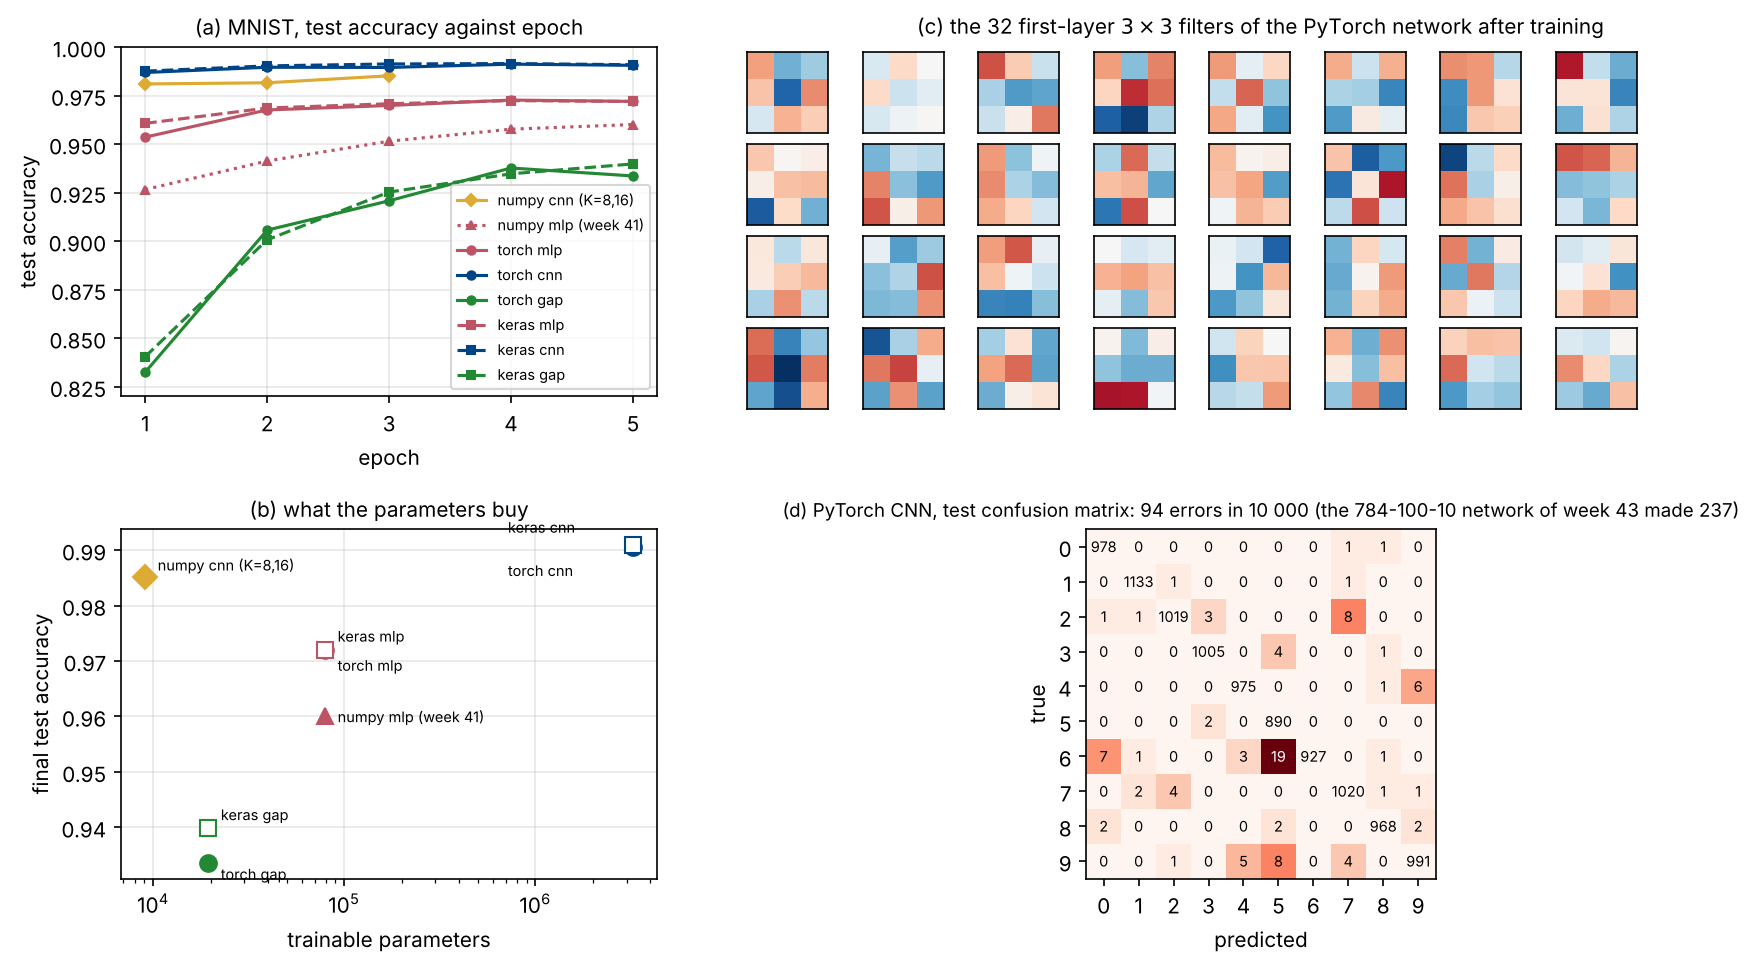

In [25]:
C = fig_mnist(runs)
print(f"{'model':28s} {'parameters':>11s}  {'test accuracy':>13s}  {'s/epoch':>8s}")
for name, r in runs.items():
    print(f"{name:28s} {r['n_params']:11d}  {r['test_accuracy']:13.4f}  {r['seconds_per_epoch']:8.0f}")
Coff = C.copy(); np.fill_diagonal(Coff, 0)
worst = np.dstack(np.unravel_index(np.argsort(-Coff.ravel())[:6], C.shape))[0]
print(f"\nPyTorch CNN, test confusion matrix: {int(Coff.sum())} errors in 10 000; largest confusions (true -> predicted: count): "
      + ", ".join(f"{i} -> {j}: {C[i, j]}" for i, j in worst))
print(C)
Image("week44_mnist.png", width=1000)

## Part 5: filters at work — a drawn house and a photograph of houses (Part 3 of the slides)

Three hand-made filters on a digit were week 43. Here the same idea on a
*house*: a $24\times24$ drawing with walls, a gabled roof, a door and a
window, and the photograph `photo1.jpg` of the 2025 week-45 folder (houses
on a square, in grey, shrunk to $360$ columns). The $3\times3$ Sobel filters
find vertical and horizontal edges, two further $3\times3$ filters find the
two slopes of the roof, and a $5\times5$ mean blurs.

The last panel of each figure is *template matching*: cut a piece out of
the picture itself — the roof of the drawn house, one double-arched window
of the photograph — subtract its mean, divide by its norm, and use it as the
filter. With the same normalisation applied to every patch of the image
(`normalised_cross_correlation`), the output is $1$ exactly where the patch
*is* the template, up to brightness and contrast, and smaller elsewhere.
The window template lights up at every window of that type — a filter that
finds windows is the beginning of a filter that finds houses. A CNN learns
such filters from the data instead of our cutting them out by hand.

First the $3\times3$ input and $2\times2$ filter of the lecture notes with
numbers, and the same product through the flattened $4\times9$ matrix.

In [2]:
def small_example():
    """The 3x3 input and 2x2 filter of the lecture notes with numbers, stride 1, no padding, and the unrolled matrix."""
    X = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]])
    W = np.array([[1.0, 2.0], [3.0, 4.0]])
    Y = cross_correlate2d(X, W)
    Wp = unrolled_matrix(W)
    return X, W, Y, Wp, Wp @ X.ravel()



X, Wf, Y, Wp, y = small_example()
print("X =\n", X, "\nW =\n", Wf, "\nY = X (cross-)correlated with W, stride 1:\n", Y)
print("the 4 x 9 matrix W' and W' X':\n", Wp, "\n", y)

X =
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]] 
W =
 [[1. 2.]
 [3. 4.]] 
Y = X (cross-)correlated with W, stride 1:
 [[37. 47.]
 [67. 77.]]
the 4 x 9 matrix W' and W' X':
 [[1. 2. 0. 3. 4. 0. 0. 0. 0.]
 [0. 1. 2. 0. 3. 4. 0. 0. 0.]
 [0. 0. 0. 1. 2. 0. 3. 4. 0.]
 [0. 0. 0. 0. 1. 2. 0. 3. 4.]] 
 [37. 47. 67. 77.]


In [3]:
HERE = os.getcwd()      # the folder of this notebook; photo1.jpg is looked for in ../../pub/week45/ipynb/figslides/ and in figslides/


def draw_house(size=24):
    """A small picture of a house: walls, a gabled roof, a door and a window; white (1) on black (0)."""
    H = np.zeros((size, size))
    H[12:22, 4:20] = 1.0                              # the walls, rows 12-21, columns 4-19
    for r in range(8):                                # the roof: a triangle with apex at row 4
        H[4 + r, 12 - r - 1:12 + r + 1] = 1.0
    H[16:22, 10:14] = 0.0                             # the door (a hole in the wall)
    H[14:17, 5:8] = 0.0                               # the window
    return H



HOUSE_FILTERS = {'vertical edges': [[-1.0, 0.0, 1.0],
                       [-2.0, 0.0, 2.0],
                       [-1.0, 0.0, 1.0]], 'horizontal edges': [[-1.0, -2.0, -1.0],
                       [0.0, 0.0, 0.0],
                       [1.0, 2.0, 1.0]], 'diagonal /': [[0.0, 1.0, 2.0],
                       [-1.0, 0.0, 1.0],
                       [-2.0, -1.0, 0.0]], 'diagonal \\': [[2.0, 1.0, 0.0],
                       [1.0, 0.0, -1.0],
                       [0.0, -1.0, -2.0]]}
HOUSE_FILTERS = {k: np.array(v) for k, v in HOUSE_FILTERS.items()}


def roof_template(house=None):
    """The roof of the drawn house itself, cut out and made zero-mean with unit norm: a template for 'a gabled roof'."""
    house = draw_house() if house is None else house
    T = house[3:13, 4:20].copy()                      # rows 3-12, columns 4-19: the triangle and a sliver of wall
    T -= T.mean()
    return T / np.linalg.norm(T)


def load_photo(path=None, width=360):
    """The photograph photo1.jpg of the 2025 week-45 notebook (houses on a square), in grey, shrunk to `width` columns."""
    from PIL import Image
    if path is None:
        candidates = [os.path.join(HERE, "..", "..", "pub", "week45", "ipynb", "figslides", "photo1.jpg"),
                      os.path.join(HERE, "figslides", "photo1.jpg"), "photo1.jpg"]
        path = next((p for p in candidates if os.path.exists(p)), candidates[0])
    im = Image.open(path).convert("L")
    h = int(round(im.size[1] * width / im.size[0]))
    im = im.resize((width, h))
    return np.asarray(im, dtype=float) / 255.0


def window_template(photo, row, col, h=14, w=9):
    """Cut one arched window out of the photograph and make it a zero-mean, unit-norm filter."""
    T = photo[row:row + h, col:col + w].copy()
    T -= T.mean()
    return T / np.linalg.norm(T)


def normalised_cross_correlation(X, T):
    """Cross-correlation of X with the template T after subtracting the local mean of every patch and dividing by its
    norm: a value of 1 means the patch IS the template up to brightness and contrast (template matching)."""
    from scipy.signal import correlate2d
    h, w = T.shape
    ones = np.ones_like(T)
    mean = correlate2d(X, ones, mode="valid") / (h * w)
    sq = correlate2d(X ** 2, ones, mode="valid")
    var = np.maximum(sq - h * w * mean ** 2, 1e-12)
    num = correlate2d(X, T, mode="valid") - mean * T.sum()
    return num / np.sqrt(var)


def house_demo(fname="week44_house.pdf", fname_photo="week44_photo.pdf"):
    """Figure 1: the drawn house, four edge maps and the roof-template map.  Figure 2: the photograph, two edge maps,
    the blur, one window cut from the photograph, and the normalised cross-correlation with it."""
    from scipy.signal import correlate2d
    house = draw_house()
    maps = {name: cross_correlate2d(house, W, padding=1) for name, W in HOUSE_FILTERS.items()}
    T_roof = roof_template(house)
    roof = normalised_cross_correlation(house, T_roof)
    fig, ax = plt.subplots(1, 6, figsize=(16, 3.1))
    ax[0].imshow(house, cmap="gray"); ax[0].set_title("a house, $24\\times24$ pixels", fontsize=10)
    titles = ["vertical edges", "horizontal edges", "diagonal edges (one way)", "diagonal edges (the other)"]
    for a, (name, Y), t in zip(ax[1:5], maps.items(), titles):
        v = np.max(np.abs(Y))
        a.imshow(Y, cmap="RdBu_r", vmin=-v, vmax=v); a.set_title(f"{t}\n$3\\times3$ filter, $P=1$: $24\\times24$", fontsize=9)
    ax[5].imshow(roof, cmap="magma", vmin=-1, vmax=1)
    r, c = np.unravel_index(np.argmax(roof), roof.shape)
    ax[5].plot(c, r, "o", mfc="none", mec="cyan", ms=16, mew=1.5)
    ax[5].set_title(f"template = the roof ($10\\times16$):\nnormalised cross-correlation, max {roof.max():.2f}", fontsize=9)
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    fig.tight_layout()
    fig.savefig(fname); fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)

    photo = load_photo()
    pmaps = {"vertical edges (Sobel)": correlate2d(photo, HOUSE_FILTERS["vertical edges"], mode="valid"),
             "horizontal edges (Sobel)": correlate2d(photo, HOUSE_FILTERS["horizontal edges"], mode="valid"),
             "blur ($5\\times5$ mean)": correlate2d(photo, np.ones((5, 5)) / 25.0, mode="valid")}
    T = window_template(photo, 79, 173, h=22, w=18)   # one double-arched window of the middle building
    ncc = normalised_cross_correlation(photo, T)
    fig, ax = plt.subplots(1, 6, figsize=(16, 3.1), gridspec_kw={"width_ratios": [1.7, 1.7, 1.7, 1.7, 0.8, 1.7]})
    ax[0].imshow(photo, cmap="gray"); ax[0].set_title(f"photo1.jpg in grey, ${photo.shape[0]}\\times{photo.shape[1]}$", fontsize=9)
    for a, (name, Y) in zip(ax[1:4], pmaps.items()):
        if "blur" in name:
            a.imshow(Y, cmap="gray"); a.set_title(name, fontsize=9)
        else:
            v = np.percentile(np.abs(Y), 99)
            a.imshow(Y, cmap="RdBu_r", vmin=-v, vmax=v); a.set_title(name, fontsize=9)
    ax[4].imshow(T, cmap="gray"); ax[4].set_title(f"template: one window\n${T.shape[0]}\\times{T.shape[1]}$ pixels", fontsize=9)
    ax[5].imshow(ncc, cmap="magma", vmin=0, vmax=1)
    peaks = np.argwhere(ncc > 0.7)
    ax[5].plot(peaks[:, 1] + T.shape[1] // 2, peaks[:, 0] + T.shape[0] // 2, ".", color="cyan", ms=3)
    ax[5].set_title("normalised cross-correlation\nwith the window; cyan: above 0.7", fontsize=9)
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    fig.tight_layout()
    fig.savefig(fname_photo); fig.savefig(fname_photo.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return {"roof_argmax": (int(r), int(c)), "roof_max": float(roof.max()), "n_peaks": int(len(peaks)),
            "ncc_max": float(ncc.max()), "photo_shape": photo.shape, "template_shape": T.shape,
            "ncc_second": float(np.sort(ncc.ravel())[-2])}


drawn house: the roof template gives its maximum 1.00 at (3, 4) (the roof)
photograph (211, 360), window template (22, 18): maximum 1.000, second largest 0.890, 24 pixels above 0.7


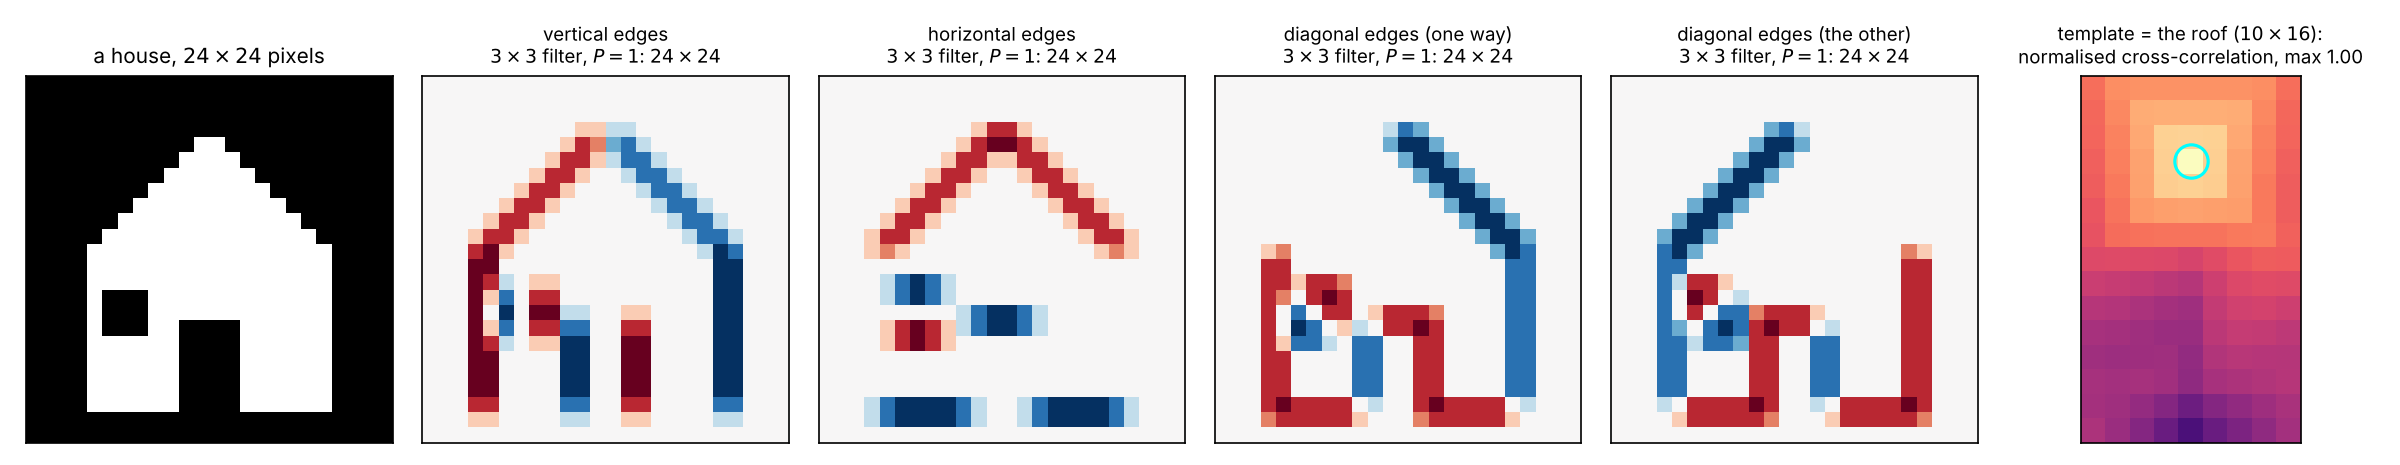

In [4]:
hd = house_demo()
print(f"drawn house: the roof template gives its maximum {hd['roof_max']:.2f} at {hd['roof_argmax']} (the roof)")
print(f"photograph {hd['photo_shape']}, window template {hd['template_shape']}: maximum {hd['ncc_max']:.3f}, "
      f"second largest {hd['ncc_second']:.3f}, {hd['n_peaks']} pixels above 0.7")
Image("week44_house.png", width=1000)

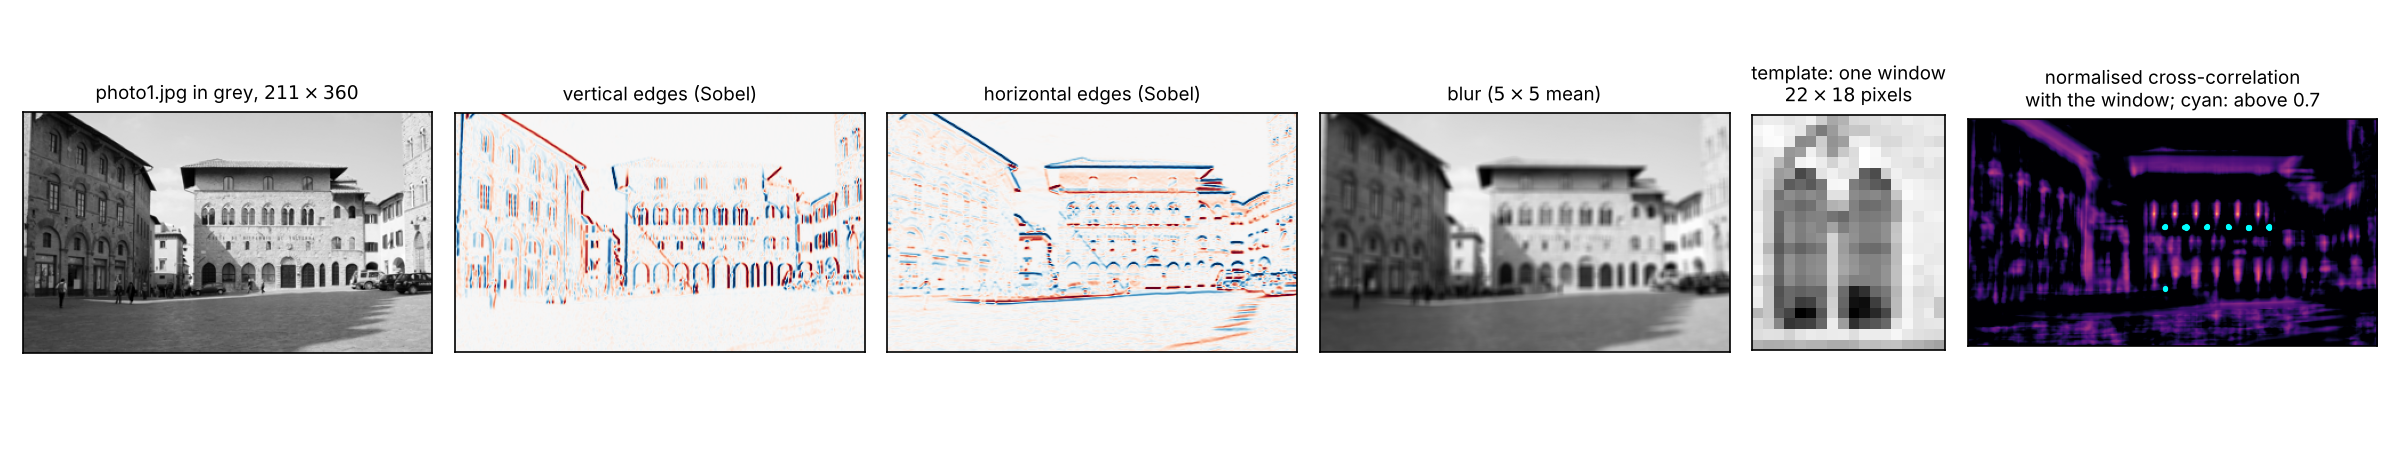

In [5]:
Image("week44_photo.png", width=1000)

## Part 6: Fourier filters (the closing frames of the slides)

The convolution theorem: for $(f*h)(t)=\int f(\tau)h(t-\tau)\,d\tau$ the
Fourier transform factorises, $\widehat{f*h}(\omega)=\hat f(\omega)\hat
h(\omega)$ — convolution in $t$ is multiplication in $\omega$. For $N$
samples the same holds with the discrete transform
$X_k=\sum_n x_n e^{-2\pi i kn/N}$ (`np.fft.fft`) and the *circular*
convolution $(h\circledast x)_n=\sum_m h_m x_{(n-m)\bmod N}$. A
convolution filter $y=h*f$ therefore multiplies every frequency component
by one number, the frequency response $H=\hat h$: $|H|$ is the gain of a
mode, $\arg H$ its phase shift, and Fourier modes are the eigenfunctions
of every convolution.

Three demonstrations. (1) A two-tone signal, $3$ Hz and $25$ Hz: its DFT
has two lines; a mask that keeps $|\nu|\le 8$ Hz returns the $3$ Hz tone
to machine precision; the three-point average $(1,2,1)/4$ has the response
$\cos^2(\Omega/2)$ and $(-1,2,-1)/4$ the complementary $\sin^2(\Omega/2)$;
and the mask is itself a convolution, with a long oscillating (sinc)
kernel — sharp in frequency means wide in time. (2) Linear against
circular convolution: $(1,2,3)*(1,1)=(1,3,5,3)$, but an FFT of length 3
wraps the last value around; pad to $N\ge L_x+L_h-1$ and the FFT product
is exact. (3) The photograph in Fourier space: its spectrum, an ideal low
pass (a blur) and high pass (the edges) by multiplication, the frequency
response of the Sobel filter, $4|\sin\Omega_x|(1+\cos\Omega_y)$, and the
Sobel map computed as $\mathrm{IDFT}(\hat h\hat P)$ — identical to the
direct cross-correlation. A CNN layer computes $z_n=\sum_r w_r x_{n+r}$,
the convolution with the reversed kernel, so its response is
$\overline{W_k}$ for real weights; with several channels the linear stage
is one small matrix per frequency, $\mathbf Z[k]=\mathbf A[k]\mathbf
X[k]$, and the ReLU, the stride and the pooling are what the frequency
picture does not cover. The full derivations are in
`BookChapters/fourier_transform_convolution_filters.tex`.

In [2]:
def fourier_1d_demo(fname="week44_fourier1d.pdf", N=256, cutoff=8.0):
    """A sampled signal with a 3 Hz and a 25 Hz component (N samples in one second): its DFT amplitudes, a frequency
    mask keeping |nu| <= cutoff, the result, and the gains of the three-point average (1,2,1)/4 and of (-1,2,-1)/4."""
    t = np.arange(N) / N
    x = np.sin(2 * np.pi * 3 * t) + 0.35 * np.sin(2 * np.pi * 25 * t)
    X = np.fft.fft(x)
    nu = np.fft.fftfreq(N, d=1.0 / N)                 # signed bin frequencies in Hz (T = 1 s)
    H = (np.abs(nu) <= cutoff).astype(float)          # the ideal low-pass mask
    y = np.fft.ifft(H * X).real
    # the same filtering by circular convolution with the mask's impulse response
    h = np.fft.ifft(H).real
    y_conv = np.array([np.sum(h * np.roll(x[::-1], n + 1)) for n in range(N)])   # (h (*) x)_n = sum_m h_m x_{n-m}
    Omega = np.linspace(0, np.pi, 200)
    low = np.array([np.sum(np.array([0.25, 0.5, 0.25]) * np.exp(-1j * Omega_ * np.array([-1, 0, 1]))) for Omega_ in Omega]).real
    high = np.array([np.sum(np.array([-0.25, 0.5, -0.25]) * np.exp(-1j * Omega_ * np.array([-1, 0, 1]))) for Omega_ in Omega]).real
    x_low = 0.25 * np.roll(x, 1) + 0.5 * x + 0.25 * np.roll(x, -1)
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.1))
    ax[0].plot(t, x, color=GREY, lw=1, label="input $x_n$")
    ax[0].plot(t, y, color=BLUE, lw=2, label=f"mask $|\\nu|\\leq{cutoff:g}$ Hz")
    ax[0].plot(t, x_low, color=RED, lw=1.2, ls="--", label="three-point average")
    ax[0].set_xlabel("$t$ (s)"); ax[0].legend(fontsize=7); ax[0].set_title("(a) $x_n=\\sin(2\\pi 3t_n)+0.35\\sin(2\\pi 25t_n)$", fontsize=9)
    k = np.arange(N // 2)
    ax[1].stem(k, 2 * np.abs(X[:N // 2]) / N, linefmt=GREY, markerfmt=" ", basefmt=" ")
    ax[1].stem(k, 2 * np.abs((H * X)[:N // 2]) / N, linefmt=BLUE, markerfmt=" ", basefmt=" ")
    ax[1].axvline(cutoff, color=BLUE, ls=":", lw=1)
    ax[1].set_xlim(0, 40); ax[1].set_xlabel("$\\nu$ (Hz)"); ax[1].set_ylabel("$2|X_k|/N$")
    ax[1].set_title("(b) the DFT: two lines; the mask keeps one", fontsize=9)
    ax[2].plot(Omega, low, color=BLUE, lw=2, label="$(1,2,1)/4$: $\\cos^2(\\Omega/2)$")
    ax[2].plot(Omega, high, color=RED, lw=2, label="$(-1,2,-1)/4$: $\\sin^2(\\Omega/2)$")
    ax[2].plot(2 * np.pi * np.array([3, 25]) / N, np.cos(np.pi * np.array([3, 25]) / N) ** 2, "o", color=BLUE, ms=6)
    ax[2].set_xlabel("$\\Omega$ (radians per sample)"); ax[2].set_ylabel("gain $|H(\\Omega)|$")
    ax[2].set_xticks([0, np.pi / 2, np.pi]); ax[2].set_xticklabels(["0", "$\\pi/2$", "$\\pi$"]); ax[2].legend(fontsize=7)
    ax[2].set_title("(c) gain of two three-tap filters", fontsize=9)
    ax[3].plot(np.arange(-N // 2, N // 2) / N, np.fft.fftshift(h) * N, color=BLUE, lw=1.5)
    ax[3].set_xlim(-0.25, 0.25); ax[3].set_xlabel("$t$ (s)"); ax[3].set_ylabel("$N\\,h_n$")
    ax[3].set_title(f"(d) the mask as a convolution kernel: $\\max|y-h\\circledast x|={np.max(np.abs(y - y_conv)):.0e}$", fontsize=9)
    for a in ax:
        a.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(fname); fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    amp = {3: 2 * np.abs(X[3]) / N, 25: 2 * np.abs(X[25]) / N}
    gains = {3: float(np.cos(np.pi * 3 / N) ** 2), 25: float(np.cos(np.pi * 25 / N) ** 2)}
    return {"amplitudes": amp, "max_residual_25Hz": float(np.max(np.abs(y - np.sin(2 * np.pi * 3 * t)))),
            "three_point_gains": gains, "mask_vs_convolution": float(np.max(np.abs(y - y_conv)))}


def fft_convolution_check():
    """Linear against circular convolution: x = (1,2,3), h = (1,1); FFT length 3 wraps around, length 4 is exact."""
    x, h = np.array([1.0, 2.0, 3.0]), np.array([1.0, 1.0])
    lin = np.convolve(x, h)
    circ3 = np.fft.ifft(np.fft.fft(x, 3) * np.fft.fft(h, 3)).real
    circ4 = np.fft.ifft(np.fft.fft(x, 4) * np.fft.fft(h, 4)).real
    return lin, circ3, circ4


DFT amplitudes 2|X_k|/N at 3 and 25 Hz: 1.000, 0.350
after the 8 Hz mask: max |y_n - sin(2 pi 3 t_n)| = 1.8e-15
gain of the three-point average at 3 Hz and 25 Hz: 0.9986, 0.9088
the mask applied by FFT against the circular convolution with its kernel: max difference 3.3e-16
(1,2,3)*(1,1): np.convolve [1. 3. 5. 3.]; FFT of length 3 [4. 3. 5.] (wrapped); FFT of length 4 [1. 3. 5. 3.]


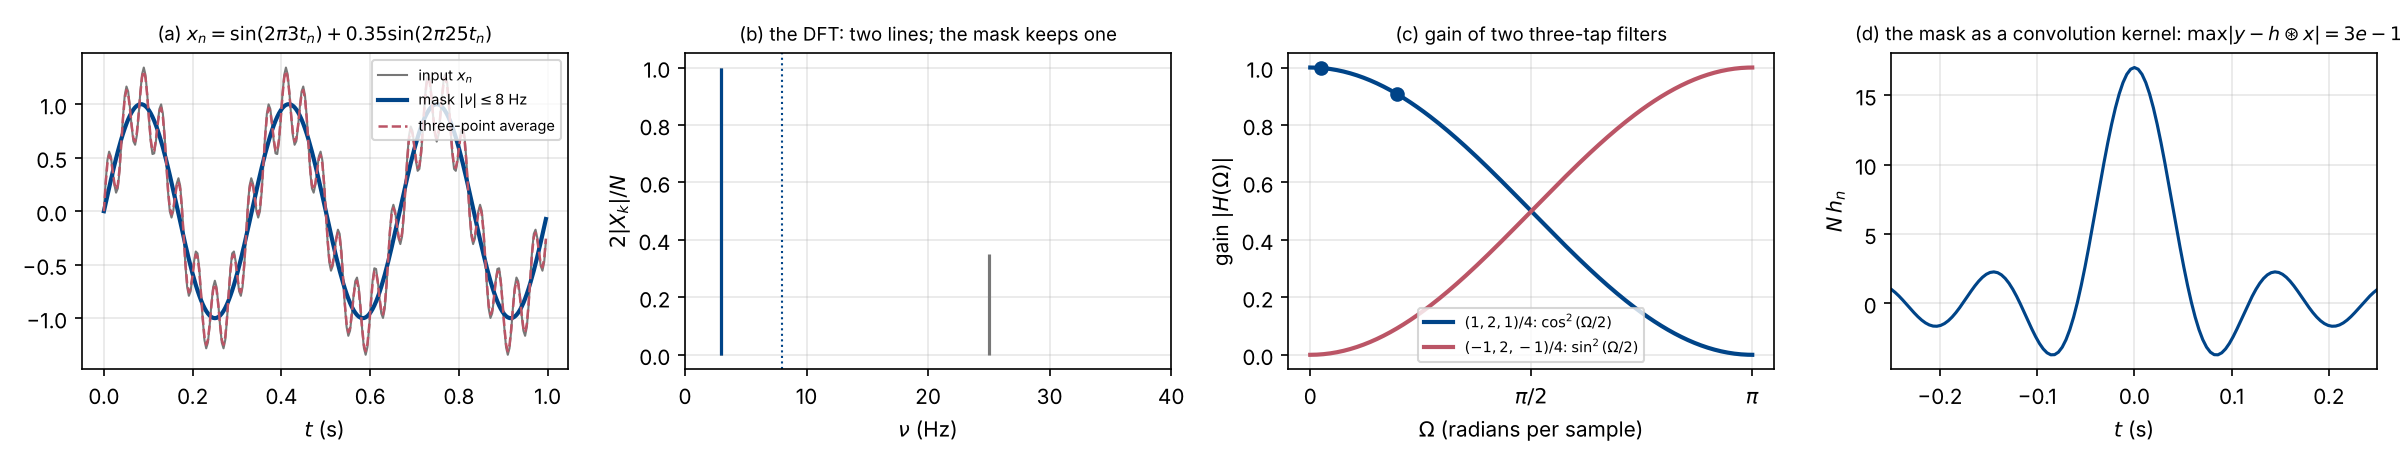

In [3]:
f1 = fourier_1d_demo()
print(f"DFT amplitudes 2|X_k|/N at 3 and 25 Hz: {f1['amplitudes'][3]:.3f}, {f1['amplitudes'][25]:.3f}")
print(f"after the 8 Hz mask: max |y_n - sin(2 pi 3 t_n)| = {f1['max_residual_25Hz']:.1e}")
print(f"gain of the three-point average at 3 Hz and 25 Hz: {f1['three_point_gains'][3]:.4f}, {f1['three_point_gains'][25]:.4f}")
print(f"the mask applied by FFT against the circular convolution with its kernel: max difference {f1['mask_vs_convolution']:.1e}")
lin, c3, c4 = fft_convolution_check()
print(f"(1,2,3)*(1,1): np.convolve {lin}; FFT of length 3 {np.round(c3, 10)} (wrapped); FFT of length 4 {np.round(c4, 10)}")
Image("week44_fourier1d.png", width=1000)

In [4]:
def fourier_2d_demo(fname="week44_fourier2d.pdf", radius=25):
    """The photograph in Fourier space: log amplitude spectrum, an ideal low-pass and high-pass mask applied by
    multiplication, and the Sobel vertical-edge filter applied once by cross-correlation and once by FFT."""
    from scipy.signal import correlate2d
    photo = load_photo()
    Hh, Ww = photo.shape
    P = np.fft.fft2(photo)
    ky = np.fft.fftfreq(Hh) * Hh                      # cycles per image, signed
    kx = np.fft.fftfreq(Ww) * Ww
    KY, KX = np.meshgrid(ky, kx, indexing="ij")
    R = np.sqrt(KX ** 2 + KY ** 2)
    low = (R <= radius).astype(float)
    p_low = np.fft.ifft2(low * P).real
    p_high = np.fft.ifft2((1 - low) * P).real
    # the Sobel filter through the FFT: embed the 3x3 kernel in an H x W array with its centre at (0,0), reversed
    W = HOUSE_FILTERS["vertical edges"]
    hk = np.zeros((Hh, Ww))
    for i in range(3):
        for j in range(3):
            hk[(-(i - 1)) % Hh, (-(j - 1)) % Ww] = W[i, j]      # cross-correlation = convolution with the reversed kernel
    sobel_fft = np.fft.ifft2(np.fft.fft2(hk) * P).real
    sobel_direct = correlate2d(photo, W, mode="same", boundary="wrap")
    gain = np.abs(np.fft.fftshift(np.fft.fft2(hk)))
    fig, ax = plt.subplots(1, 5, figsize=(16, 3.3))
    ax[0].imshow(np.log10(np.abs(np.fft.fftshift(P)) + 1), cmap="magma")
    ax[0].set_title("(a) $\\log_{10}|\\hat P|$ of the photograph\n(zero frequency at the centre)", fontsize=9)
    ax[1].imshow(p_low, cmap="gray"); ax[1].set_title(f"(b) low pass: keep $|k|\\leq{radius}$ cycles per image", fontsize=9)
    v = np.percentile(np.abs(p_high), 99)
    ax[2].imshow(p_high, cmap="gray", vmin=-v, vmax=v); ax[2].set_title(f"(c) high pass: keep $|k|>{radius}$", fontsize=9)
    ax[3].imshow(gain, cmap="magma", extent=[-Ww / 2, Ww / 2, Hh / 2, -Hh / 2])
    ax[3].set_title("(d) gain $|\\hat h|$ of the Sobel filter, $4|\\sin\\Omega_x|(1+\\cos\\Omega_y)$,\n$\\Omega_x=2\\pi k_x/W$, $\\Omega_y=2\\pi k_y/H$", fontsize=9)
    ax[3].set_xlabel("$k_x$"); ax[3].set_ylabel("$k_y$")
    v = np.percentile(np.abs(sobel_fft), 99)
    ax[4].imshow(sobel_fft, cmap="RdBu_r", vmin=-v, vmax=v)
    ax[4].set_title(f"(e) Sobel by FFT; max difference to the\ndirect cross-correlation: {np.max(np.abs(sobel_fft - sobel_direct)):.0e}", fontsize=9)
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    fig.tight_layout()
    fig.savefig(fname); fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return {"shape": photo.shape, "sobel_fft_vs_direct": float(np.max(np.abs(sobel_fft - sobel_direct))),
            "kept_fraction": float(low.mean())}


photograph (211, 360): the low-pass mask keeps 2.6% of the Fourier coefficients; Sobel by FFT against the direct cross-correlation: max difference 3.1e-15


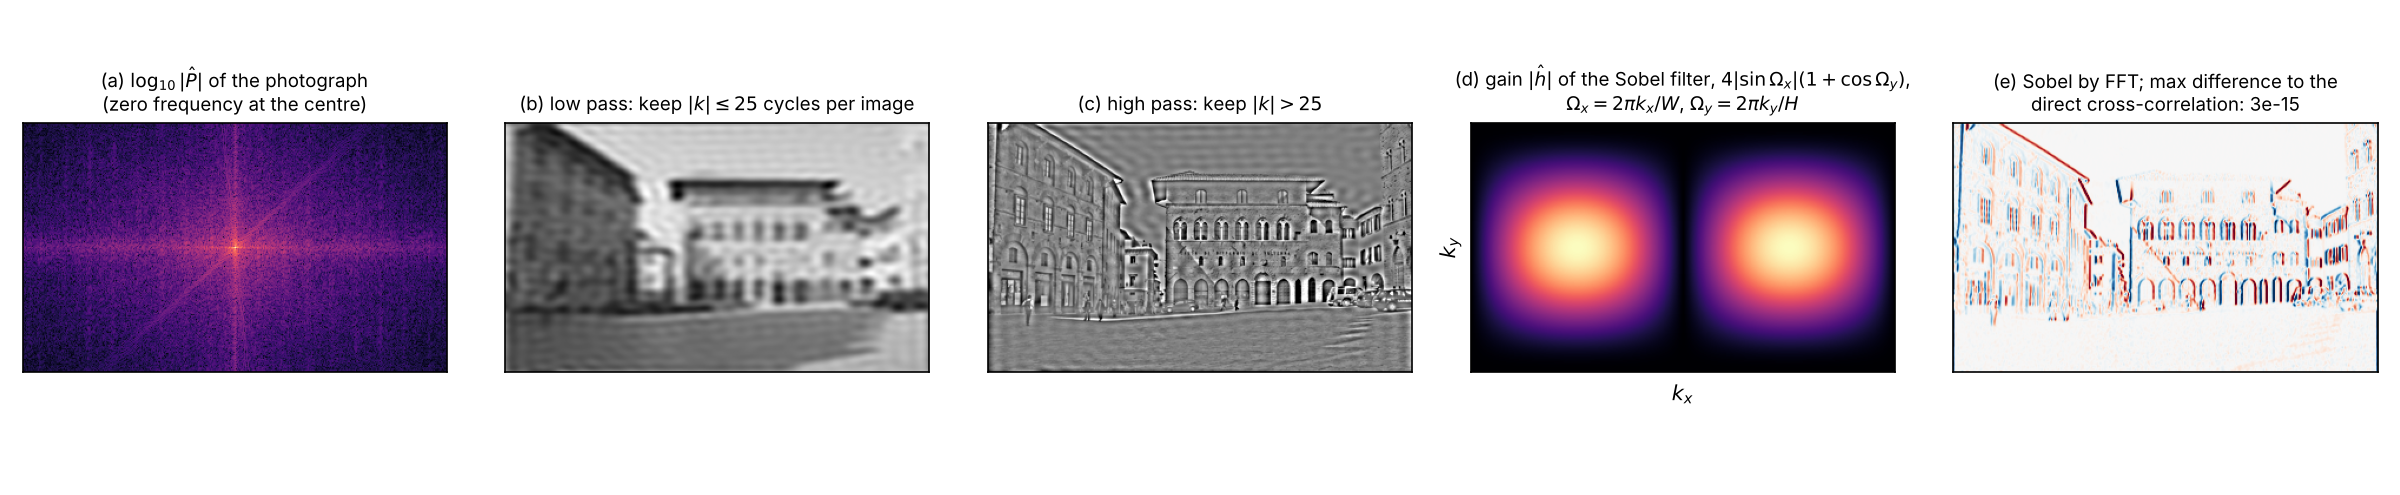

In [5]:
f2 = fourier_2d_demo()
print(f"photograph {f2['shape']}: the low-pass mask keeps {100 * f2['kept_fraction']:.1f}% of the Fourier coefficients; "
      f"Sobel by FFT against the direct cross-correlation: max difference {f2['sobel_fft_vs_direct']:.1e}")
Image("week44_fourier2d.png", width=1000)

**Reading the results.** Three comparisons.

1. *CNN against the Project 2 network.* With the same data and optimiser
   the convolutional network removes two thirds of the dense network's test
   errors, and the week-43 error bar $\sqrt{p(1-p)/n}\approx0.001$ at $99\%$
   says the gap is many standard errors wide. Its 94 errors sit in a few
   pairs — $6\to5$, $2\to7$, $9\to5$, $4\to9$ — where the week-43 matrix of
   the dense network had 237, led by $4\to9$.
2. *Where the parameters are.* The $3.2$-million dense head against the
   $19\,466$-parameter GAP head: a factor $167$ in parameters buys a few
   points of accuracy after five epochs and costs a factor two in time; the
   GAP network is still climbing when the run stops while the dense one is
   flat after the first epoch (panel a). On a harder problem, with the
   overfitting that three million parameters invite, the ordering commonly
   reverses; on MNIST in five epochs it does not. Stated honestly: the dense
   head is not pure waste — but everything this chapter has been about
   applies to $0.58\%$ of it.
3. *Our NumPy network.* With $9\,098$ parameters and three epochs it is
   already past the $79\,510$-parameter dense network of week 41: the
   architecture, not the parameter count, is what the digits reward. It is
   also an order of magnitude slower per epoch than the frameworks —
   `im2col` in NumPy is for understanding what the library does, not for
   replacing it.

PyTorch and Keras do not give identical accuracies and should not: the
initialisation, the shuffling and the dropout masks are drawn from different
generators, and the epoch-to-epoch variation within one run is already
about $0.004$. Section 10.12.3 settled that they implement the *same* model
to $10^{-16}$; what differs here is the noise of a stochastic optimiser.
Panel (c) shows the thirty-two first-layer filters of the trained PyTorch
network — the same oriented opposed-sign pairs as the eight NumPy filters of
Part 4a (Figure 10.13d against Figure 10.12c).

Every number in this part has a learning rate, a batch size, a number of
epochs, a dropout rate and a width behind it that nobody chose. **Tomorrow**
is about choosing them: cross-validation for your Project 2 network, with
your own code wrapped as a `scikit-learn` estimator inside `KFold`,
`cross_validate`, `GridSearchCV` and `validation_curve` — the structure of
this week's exercises (`exercisesweek44.ipynb`, deadline Friday October
30). Today's CNN is not required for Project 2, but cross-validated the
same way and compared honestly with the dense network (both tuned on
validation folds, test set touched once) it is a fine addition.